# Decoder Comparison

Compares all decoding pipelines against `OptimalDecode` (joint) across random and KNN permutations.

| Key | Decoder | Notes |
|---|---|---|
| `combined` | OptimalDecode (multi-CS) | Baseline |
| `montoya` | MontoyaDecode (split + optimal CS repair) | Exact, should match baseline |
| `combined_single` | OptimalDecode (single-CS) | May be infeasible |
| `battery` | BatteryDecode (multi-CS) | Always valid |
| `battery_single` | BatteryDecode (single-CS) | Always valid |
| `bhga` | BHGA insertion | May be infeasible |
| `baco` | BACO insertStationByRemove | May be infeasible |
| `caco` | CACO insertStationBySimpleEnum | May be infeasible |
| `frvcpy` | FRVCPY exact | May be infeasible |

In [1]:
import math
import json
import statistics
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd
import seaborn as sns
from IPython.display import display

plt.rcParams.update({
    "font.family":        "serif",
    "mathtext.fontset":   "cm",
    "font.size":          6,
    "axes.labelsize":     7,
    "xtick.labelsize":    5,
    "ytick.labelsize":    5,
    "figure.dpi":         200,
    "savefig.dpi":        600,
    "savefig.bbox":       "tight",
    "savefig.pad_inches": 0.02,
})

In [2]:
with open('../results/decoder_comparison_random1000.json') as f:
    random_results = json.load(f)

with open('../results/decoder_comparison_knn1000.json') as f:
    knn_results = json.load(f)

print(f"Random: {len(random_results)} instances, {len(next(iter(random_results.values())))} permutations each")
print(f"KNN:    {len(knn_results)} instances, {len(next(iter(knn_results.values())))} permutations each")

Random: 17 instances, 1000 permutations each
KNN:    17 instances, 1000 permutations each


In [3]:
# Algorithm definitions: (label, cost_key, solved_key or None)
ALGORITHMS = [
    ('Battery',         'battery',         'battery_solved'),
    ('BatterySingleCS', 'battery_single',  'battery_single_solved'),
    ('BHGA',            'bhga',            'bhga_solved'),
    ('BACO',            'baco',            'baco_solved'),
    ('CACO',            'caco',            'caco_solved'),
    ('FRVCPY',          'frvcpy',          'frvcpy_solved'),
    ('Montoya',         'montoya',         'montoya_solved'),
]

ALG_COLORS = ['#377eb8', '#4daf4a', '#984ea3', '#ff7f00', '#e41a1c', '#a65628', '#f781bf']

# Timing pipelines: (label, lambda returning time in ms from a single permutation record)
TIMING_PIPELINES = [
    ('Optimal',            lambda p: p['t_optimal'] / 1e6),
    ('Split+Battery',      lambda p: (p['t_split'] + p['t_battery']) / 1e6),
    ('Split+BatterySingle',lambda p: (p['t_split'] + p['t_battery_single']) / 1e6),
    ('Split+BHGA',         lambda p: (p['t_split'] + p['t_bhga']) / 1e6),
    ('Split+BACO',         lambda p: (p['t_split'] + p['t_baco']) / 1e6),
    ('Split+CACO',         lambda p: (p['t_split'] + p['t_caco']) / 1e6),
    ('Split+FRVCPY',       lambda p: (p['t_split'] + p['t_frvcpy']) / 1e6),
    ('Montoya',            lambda p: p['t_montoya'] / 1e6),  # does its own split
]
TIMING_COLORS = ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3', '#ff7f00', '#a65628', '#f781bf', '#999999']


def _style_ax(ax):
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(0.5)
    ax.spines["bottom"].set_linewidth(0.5)
    ax.tick_params(width=0.5, length=3, direction="out")


def sorted_instances(results):
    """Sort instance names by numeric customer count extracted from the name."""
    def _sort_key(name):
        # e.g. "E-n22-k4" -> 22, "X-n1001-k43" -> 1001
        parts = name.split('-')
        for p in parts:
            if p.startswith('n') and p[1:].isdigit():
                return int(p[1:])
        return 0
    return sorted(results.keys(), key=_sort_key)


def customer_count(name):
    parts = name.split('-')
    for p in parts:
        if p.startswith('n') and p[1:].isdigit():
            return int(p[1:])
    return 0


def _smooth_log_curve(xs, ys, points_per_segment=24):
    """Smooth a positive series in log-space using cubic Hermite interpolation."""
    xs = np.asarray(xs, dtype=float)
    ys = np.asarray(ys, dtype=float)
    if len(xs) < 3:
        return xs, ys

    log_ys = np.log10(np.maximum(ys, 1e-12))
    slopes = np.empty_like(log_ys)
    slopes[0] = log_ys[1] - log_ys[0]
    slopes[-1] = log_ys[-1] - log_ys[-2]
    slopes[1:-1] = 0.5 * (log_ys[2:] - log_ys[:-2])

    smooth_xs = []
    smooth_log_ys = []
    for i in range(len(xs) - 1):
        t = np.linspace(0.0, 1.0, points_per_segment, endpoint=False)
        h00 = 2 * t**3 - 3 * t**2 + 1
        h10 = t**3 - 2 * t**2 + t
        h01 = -2 * t**3 + 3 * t**2
        h11 = t**3 - t**2
        seg_x = xs[i] + (xs[i + 1] - xs[i]) * t
        seg_y = (
            h00 * log_ys[i]
            + h10 * slopes[i]
            + h01 * log_ys[i + 1]
            + h11 * slopes[i + 1]
        )
        smooth_xs.append(seg_x)
        smooth_log_ys.append(seg_y)

    smooth_xs.append(np.array([xs[-1]]))
    smooth_log_ys.append(np.array([log_ys[-1]]))
    return np.concatenate(smooth_xs), 10 ** np.concatenate(smooth_log_ys)

In [4]:
def plot_distributions(results, alg_label, cost_key, solved_key, perm_type, save_dir):
    """Plot per-instance histograms of percentage gap from optimal for one algorithm."""
    names = sorted_instances(results)
    n = len(names)
    cols = 3
    rows = math.ceil(n / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(3.4 * cols, 2.2 * rows))
    axes_flat = axes.flatten()

    save_dir = Path(save_dir)
    save_dir.mkdir(parents=True, exist_ok=True)

    for i, name in enumerate(names):
        perms = results[name]
        if solved_key:
            gaps = [100 * (p[cost_key] - p['combined']) / p['combined']
                    for p in perms if p.get(solved_key, True)]
        else:
            gaps = [100 * (p[cost_key] - p['combined']) / p['combined']
                    for p in perms]

        ax = axes_flat[i]
        ax.hist(gaps, bins=30, color='#2c5f8a', edgecolor='white', alpha=0.75, linewidth=0.3)
        ax.axvline(0, color='#b5342e', linestyle='--', linewidth=0.8)
        ax.set_title(name, fontsize=7)
        ax.set_xlabel('Gap from optimal (%)')
        ax.set_ylabel('Count')
        _style_ax(ax)

        # Save individual
        fig_i, ax_i = plt.subplots(figsize=(3.4, 2.2))
        ax_i.hist(gaps, bins=30, color='#2c5f8a', edgecolor='white', alpha=0.75, linewidth=0.3)
        ax_i.axvline(0, color='#b5342e', linestyle='--', linewidth=0.8)
        ax_i.set_xlabel('Gap from optimal (%)')
        ax_i.set_ylabel('Count')
        _style_ax(ax_i)
        fig_i.tight_layout()
        fig_i.savefig(save_dir / f"{name}.png")
        plt.close(fig_i)

    for j in range(n, len(axes_flat)):
        axes_flat[j].set_visible(False)

    fig.suptitle(f'{alg_label} — {perm_type}', fontsize=8, y=1.01)
    fig.tight_layout()
    plt.show()


def plot_boxplots(results, title, save_path=None):
    """One subplot per instance, one box per algorithm."""
    names = sorted_instances(results)
    n = len(names)
    cols = 3
    rows = math.ceil(n / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(3.4 * cols, 2.8 * rows))
    axes_flat = axes.flatten()

    labels = [a[0] for a in ALGORITHMS]

    for ax, name in zip(axes_flat, names):
        perms = results[name]
        data = []
        for _, cost_key, solved_key in ALGORITHMS:
            if solved_key:
                gaps = [100 * (p[cost_key] - p['combined']) / p['combined']
                        for p in perms if p.get(solved_key, True)]
            else:
                gaps = [100 * (p[cost_key] - p['combined']) / p['combined']
                        for p in perms]
            data.append(gaps)

        bp = ax.boxplot(
            data, labels=labels, patch_artist=True, widths=0.5,
            medianprops=dict(color='black', linewidth=1.0),
            flierprops=dict(marker='o', markersize=1.0, alpha=0.3, linestyle='none'),
            whiskerprops=dict(linewidth=0.6), capprops=dict(linewidth=0.6),
            boxprops=dict(linewidth=0.6),
        )
        for patch, color in zip(bp['boxes'], ALG_COLORS):
            patch.set_facecolor(color)
            patch.set_alpha(0.7)

        ax.axhline(0, color='#b5342e', linestyle='--', linewidth=0.8)
        ax.set_title(name, fontsize=7)
        ax.set_ylabel('Gap from optimal (%)')
        ax.tick_params(axis='x', labelsize=4, rotation=45)
        _style_ax(ax)

    for ax in axes_flat[n:]:
        ax.set_visible(False)

    fig.suptitle(title, fontsize=8, y=1.01)
    fig.tight_layout()
    if save_path:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path)
    plt.show()

In [5]:
def plot_ecdf(results, title, save_path=None):
    """One subplot per instance: empirical CDF of the performance gap for each algorithm."""
    names = sorted_instances(results)
    n = len(names)
    cols = 3
    rows = math.ceil(n / cols)

    # BatteryDecode and FRVCPY overlap exactly in these experiments, so draw them once.
    ecdf_series = [
        ('FR-FLA / FRVCPY', 'B/F', 'battery', 'battery_solved', '#1f77b4', 'solid', 2.0, 5),
        ('SS-FR-FLA',       'BS', 'battery_single', 'battery_single_solved', '#2ca02c', (0, (5, 2)), 1.7, 4),
        ('BHGA',             'BH', 'bhga', 'bhga_solved', '#9467bd', (0, (1, 1)), 1.6, 3),
        ('BACO',             'BA', 'baco', 'baco_solved', '#ff7f0e', (0, (7, 2)), 1.6, 2),
        ('CACO',             'CA', 'caco', 'caco_solved', '#8c564b', (0, (3, 1, 1, 1)), 1.6, 1),
        ('Montoya',          'MO', 'montoya', 'montoya_solved', '#e377c2', (0, (2, 2)), 1.6, 7),
    ]

    fig, axes = plt.subplots(rows, cols, figsize=(4.4 * cols, 2.8 * rows))
    axes_flat = axes.flatten()
    x_min = 1e-5

    for ax, name in zip(axes_flat, names):
        sns.despine(ax=ax, top=True, right=True)
        ax.axhline(1.0, color='#c0392b', linestyle='solid', linewidth=2.0,
                   alpha=0.95, zorder=6, label='FP-FLA')
        ax.set_xscale('log')
        ax.set_facecolor('#fbfbfc')
        ax.grid(axis='y', color='#d9dde3', linewidth=0.6, alpha=0.7, zorder=0)
        ax.xaxis.set_major_locator(mticker.LogLocator(base=10.0))
        ax.xaxis.set_major_formatter(mticker.LogFormatterMathtext(base=10.0))
        ax.xaxis.set_minor_locator(mticker.NullLocator())
        ax.grid(axis='x', which='major', color='#d9dde3', linewidth=0.6, alpha=0.55, zorder=0)

        perms = results[name]
        n_total = len(perms)
        subplot_max_gap = x_min
        first_visible_levels = []
        for alg_label, short_label, cost_key, solved_key, color, linestyle, linewidth, zorder in ecdf_series:
            if solved_key:
                raw_gaps = [100 * (p[cost_key] - p['combined']) / p['combined']
                        for p in perms if p.get(solved_key, True)]
            else:
                raw_gaps = [100 * (p[cost_key] - p['combined']) / p['combined']
                        for p in perms]
            if not raw_gaps:
                continue

            first_visible_levels.append(sum(g <= x_min for g in raw_gaps) / len(raw_gaps))
            gaps = [max(g, x_min) for g in raw_gaps]
            subplot_max_gap = max(subplot_max_gap, max(gaps))

            sns.ecdfplot(x=gaps, ax=ax, label=alg_label, color=color, linewidth=linewidth,
                         linestyle=linestyle, alpha=0.95)
            ax.lines[-1].set_zorder(zorder)

        x_max = 10 ** math.ceil(math.log10(subplot_max_gap))
        if x_max <= x_min:
            x_max = 1e-1
        if first_visible_levels:
            y_min = max(0.0, math.floor(min(first_visible_levels) * 10) / 10)
        else:
            y_min = 0.0
        ax.set_xlim(x_min, x_max)
        ax.set_ylim(y_min, 1.01)
        ax.set_yticks(sorted(set([y_min, *np.arange(max(y_min, 0.1), 1.01, 0.1), 1.0])))
        ax.set_ylabel('')
        ax.tick_params(axis='both', labelsize=7.5)
        ax.text(0.03, 0.90, name, transform=ax.transAxes, va='top', ha='left',
                fontsize=10.0, fontname='Sans', bbox=dict(boxstyle='round,pad=0.22', facecolor='white',
                edgecolor='none', alpha=0.8))
        _style_ax(ax)

    handles, labels = axes_flat[2].get_legend_handles_labels()
    if n < len(axes_flat):
        legend_ax = axes_flat[-1]
        legend_ax.set_axis_off()
        legend_ax.legend(handles, labels, loc='center', fontsize=10, frameon=False,
                         handlelength=3.0, labelspacing=1.0)
        for ax in axes_flat[n:-1]:
            ax.set_visible(False)
    else:
        fig.legend(handles, labels, loc='lower center', ncol=3, fontsize=7,
                   bbox_to_anchor=(0.5, -0.02), frameon=False)

    for ax in axes_flat[max(n, len(axes_flat)):]:
        ax.set_visible(False)

    fig.tight_layout()
    if save_path:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=200)
    plt.show()

## Random Permutations — Distributions

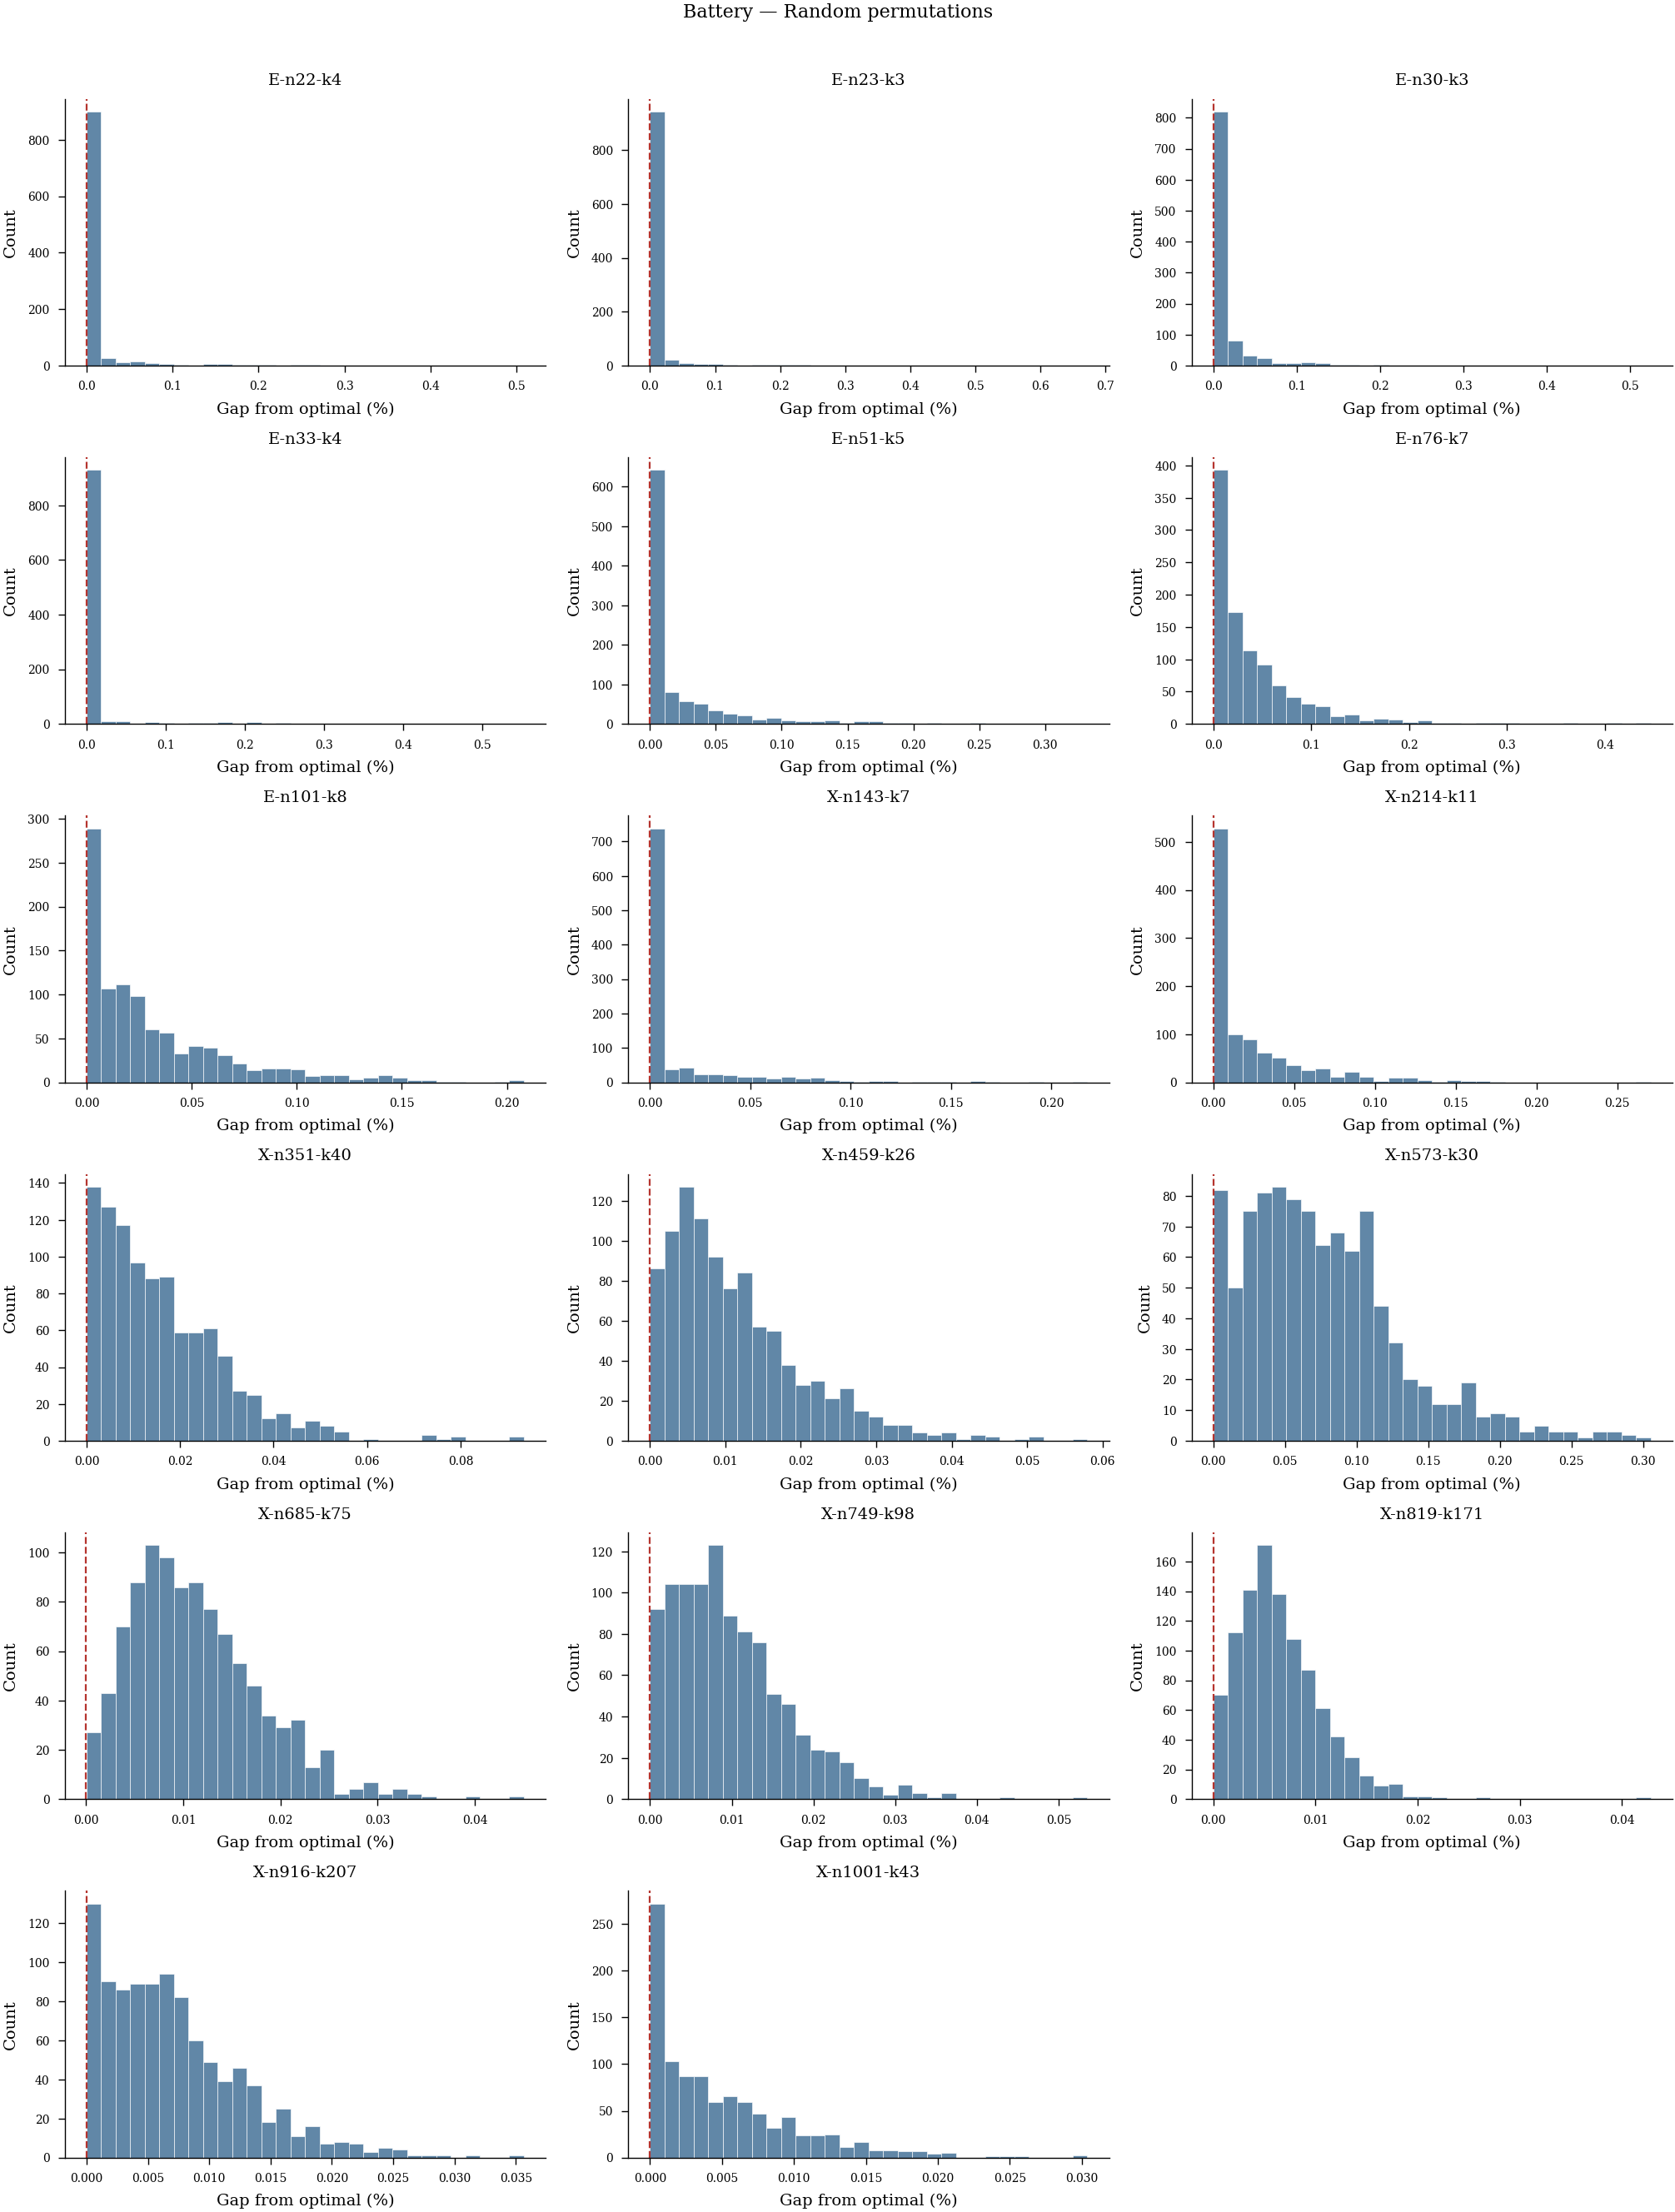

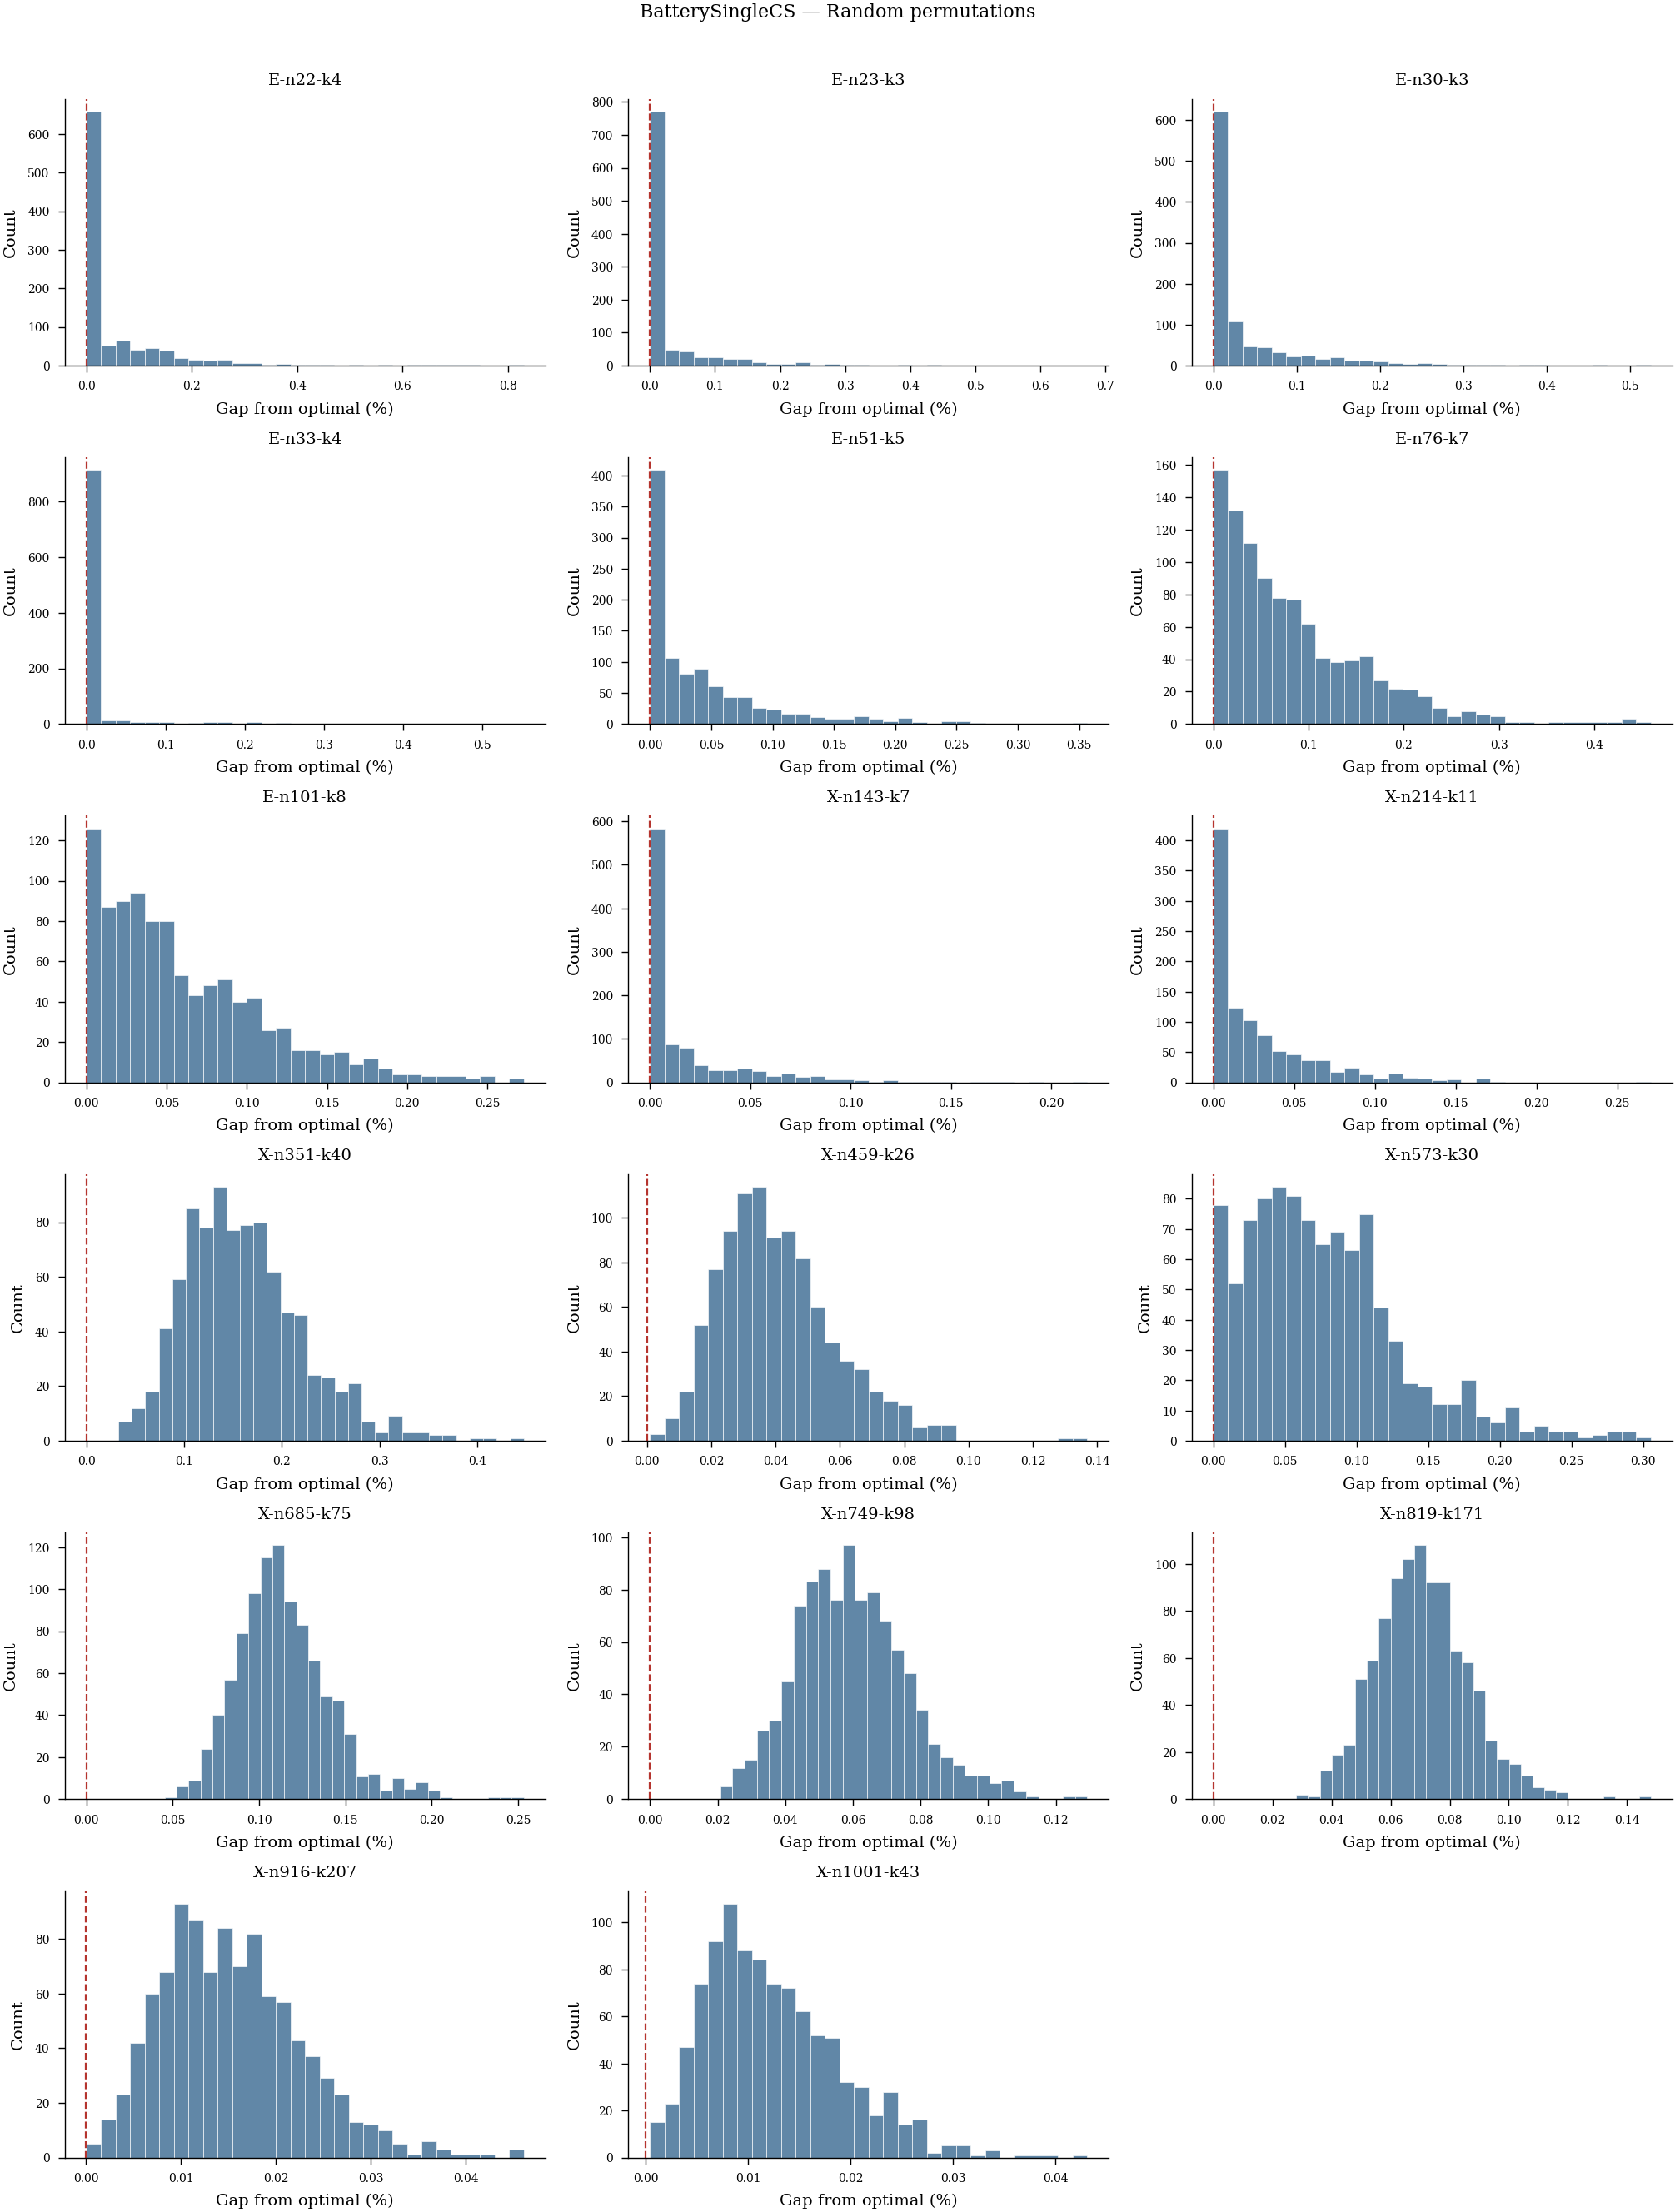

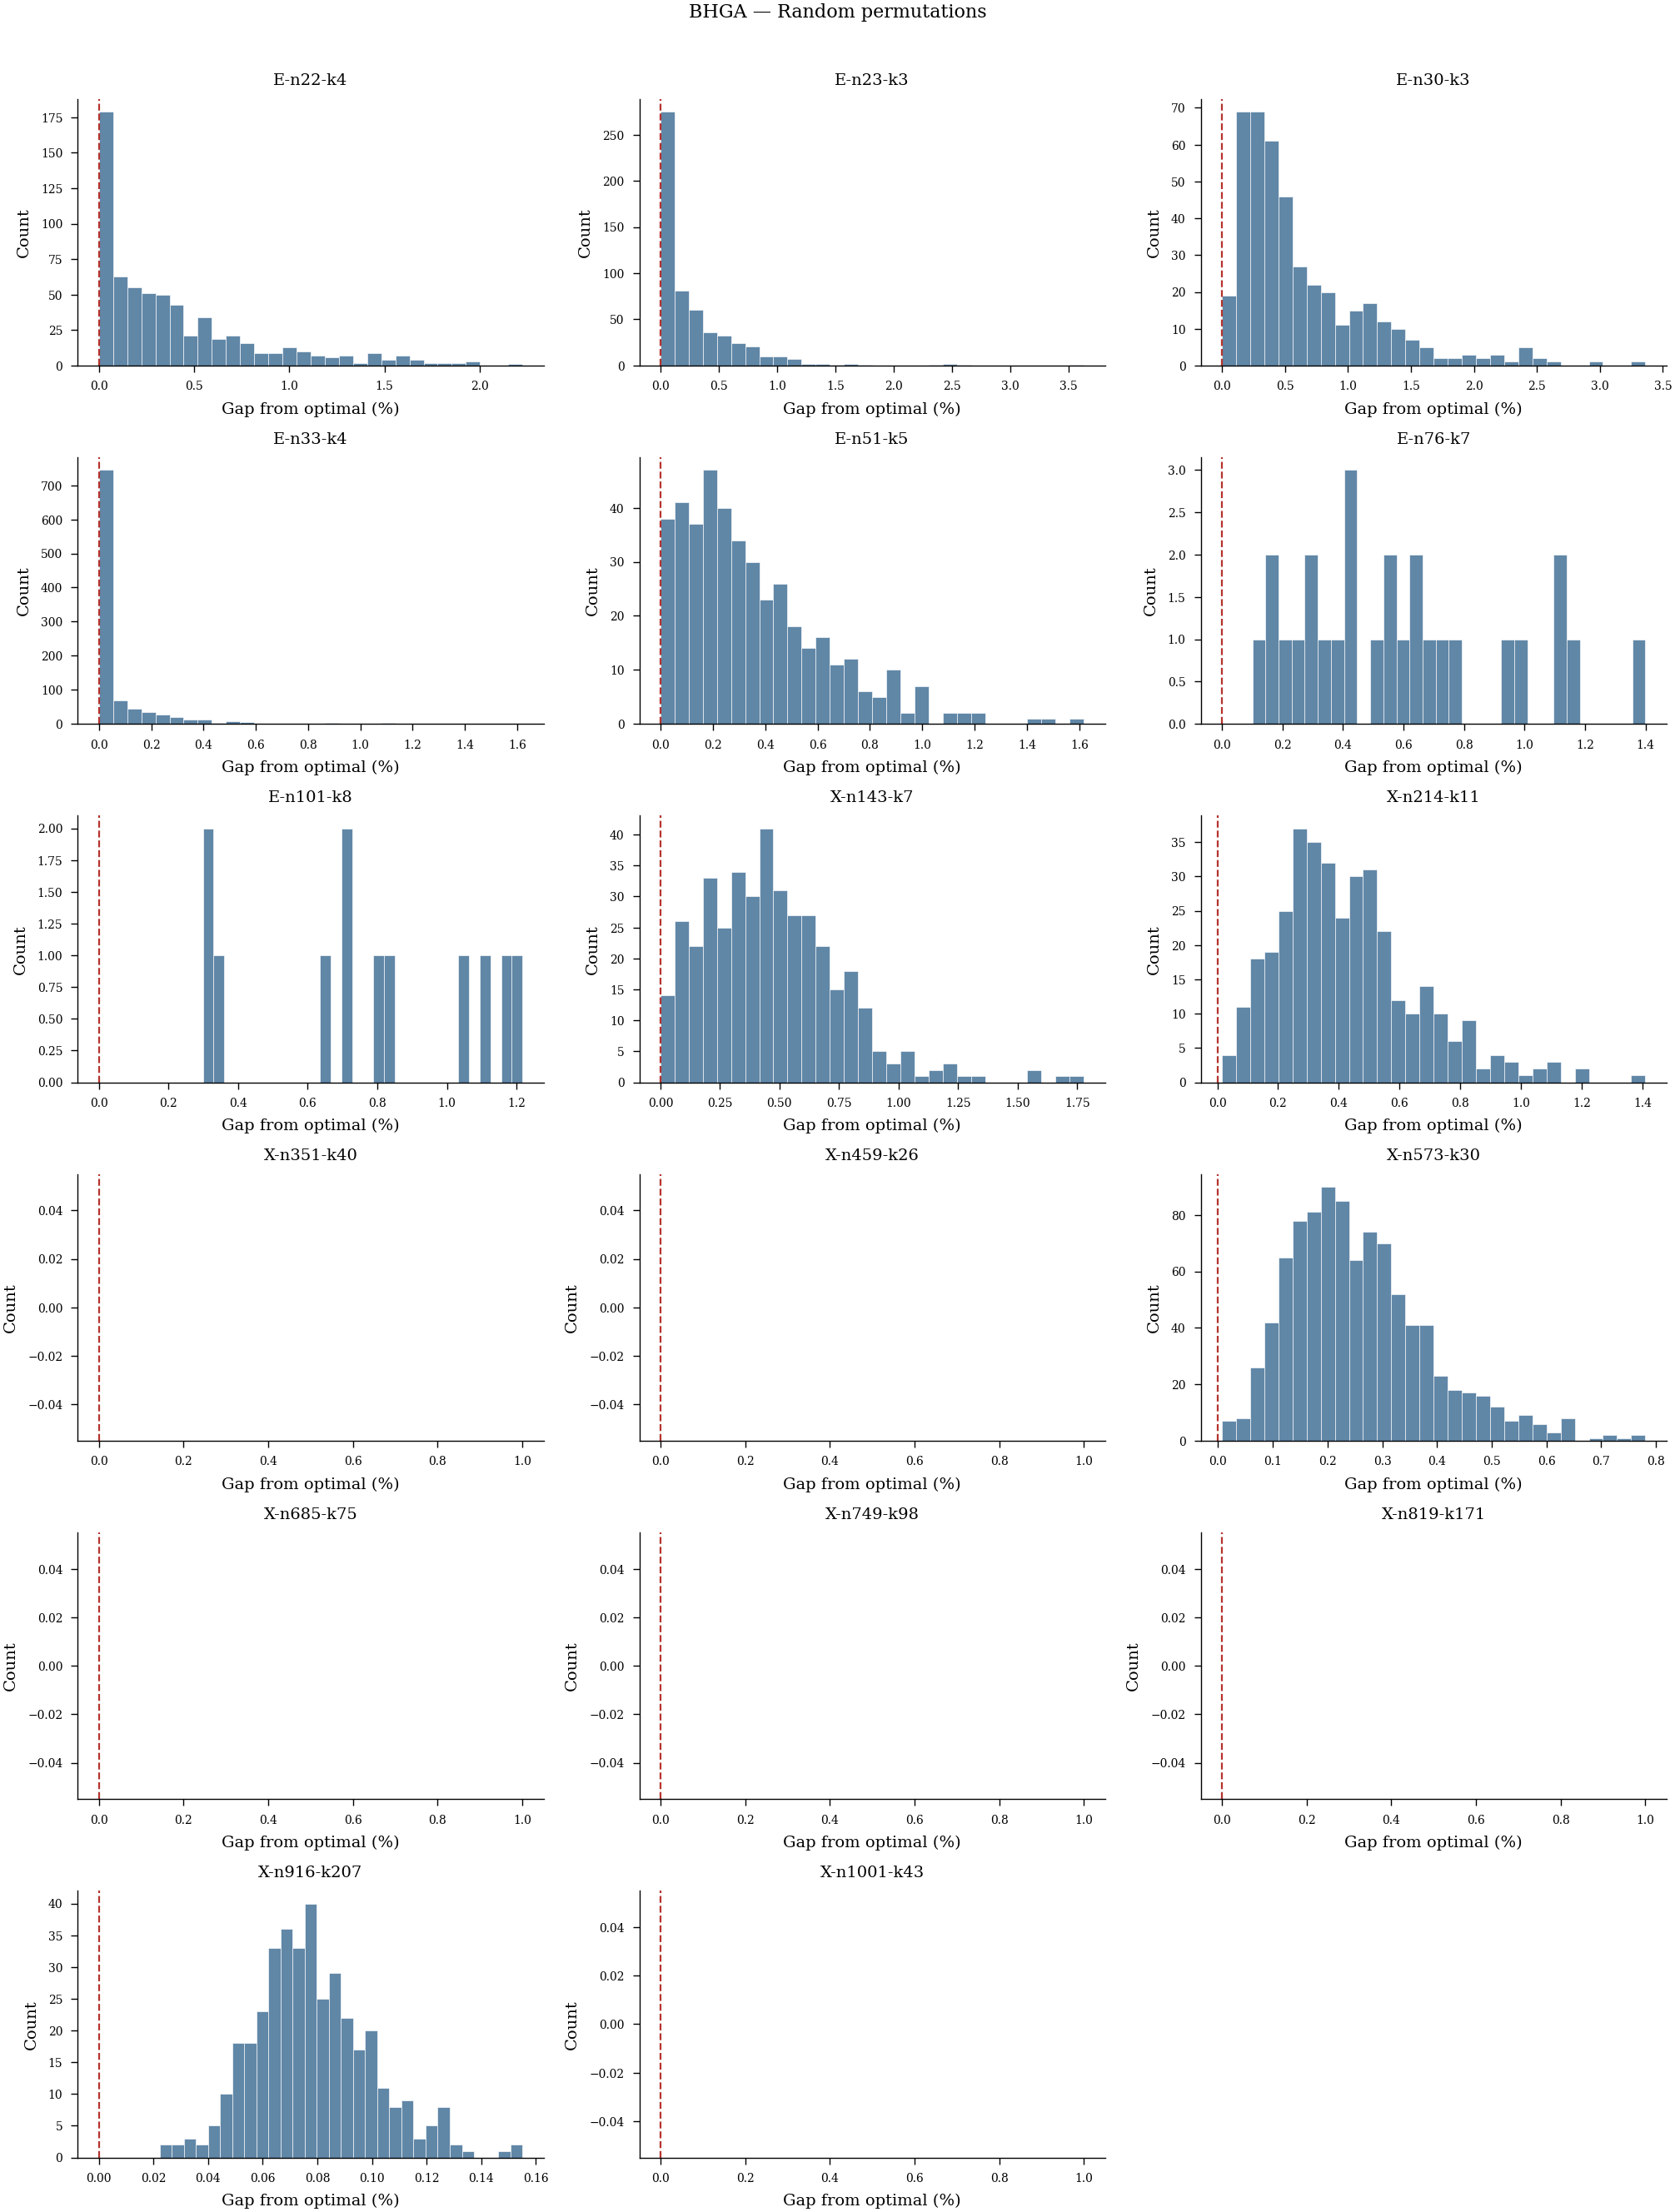

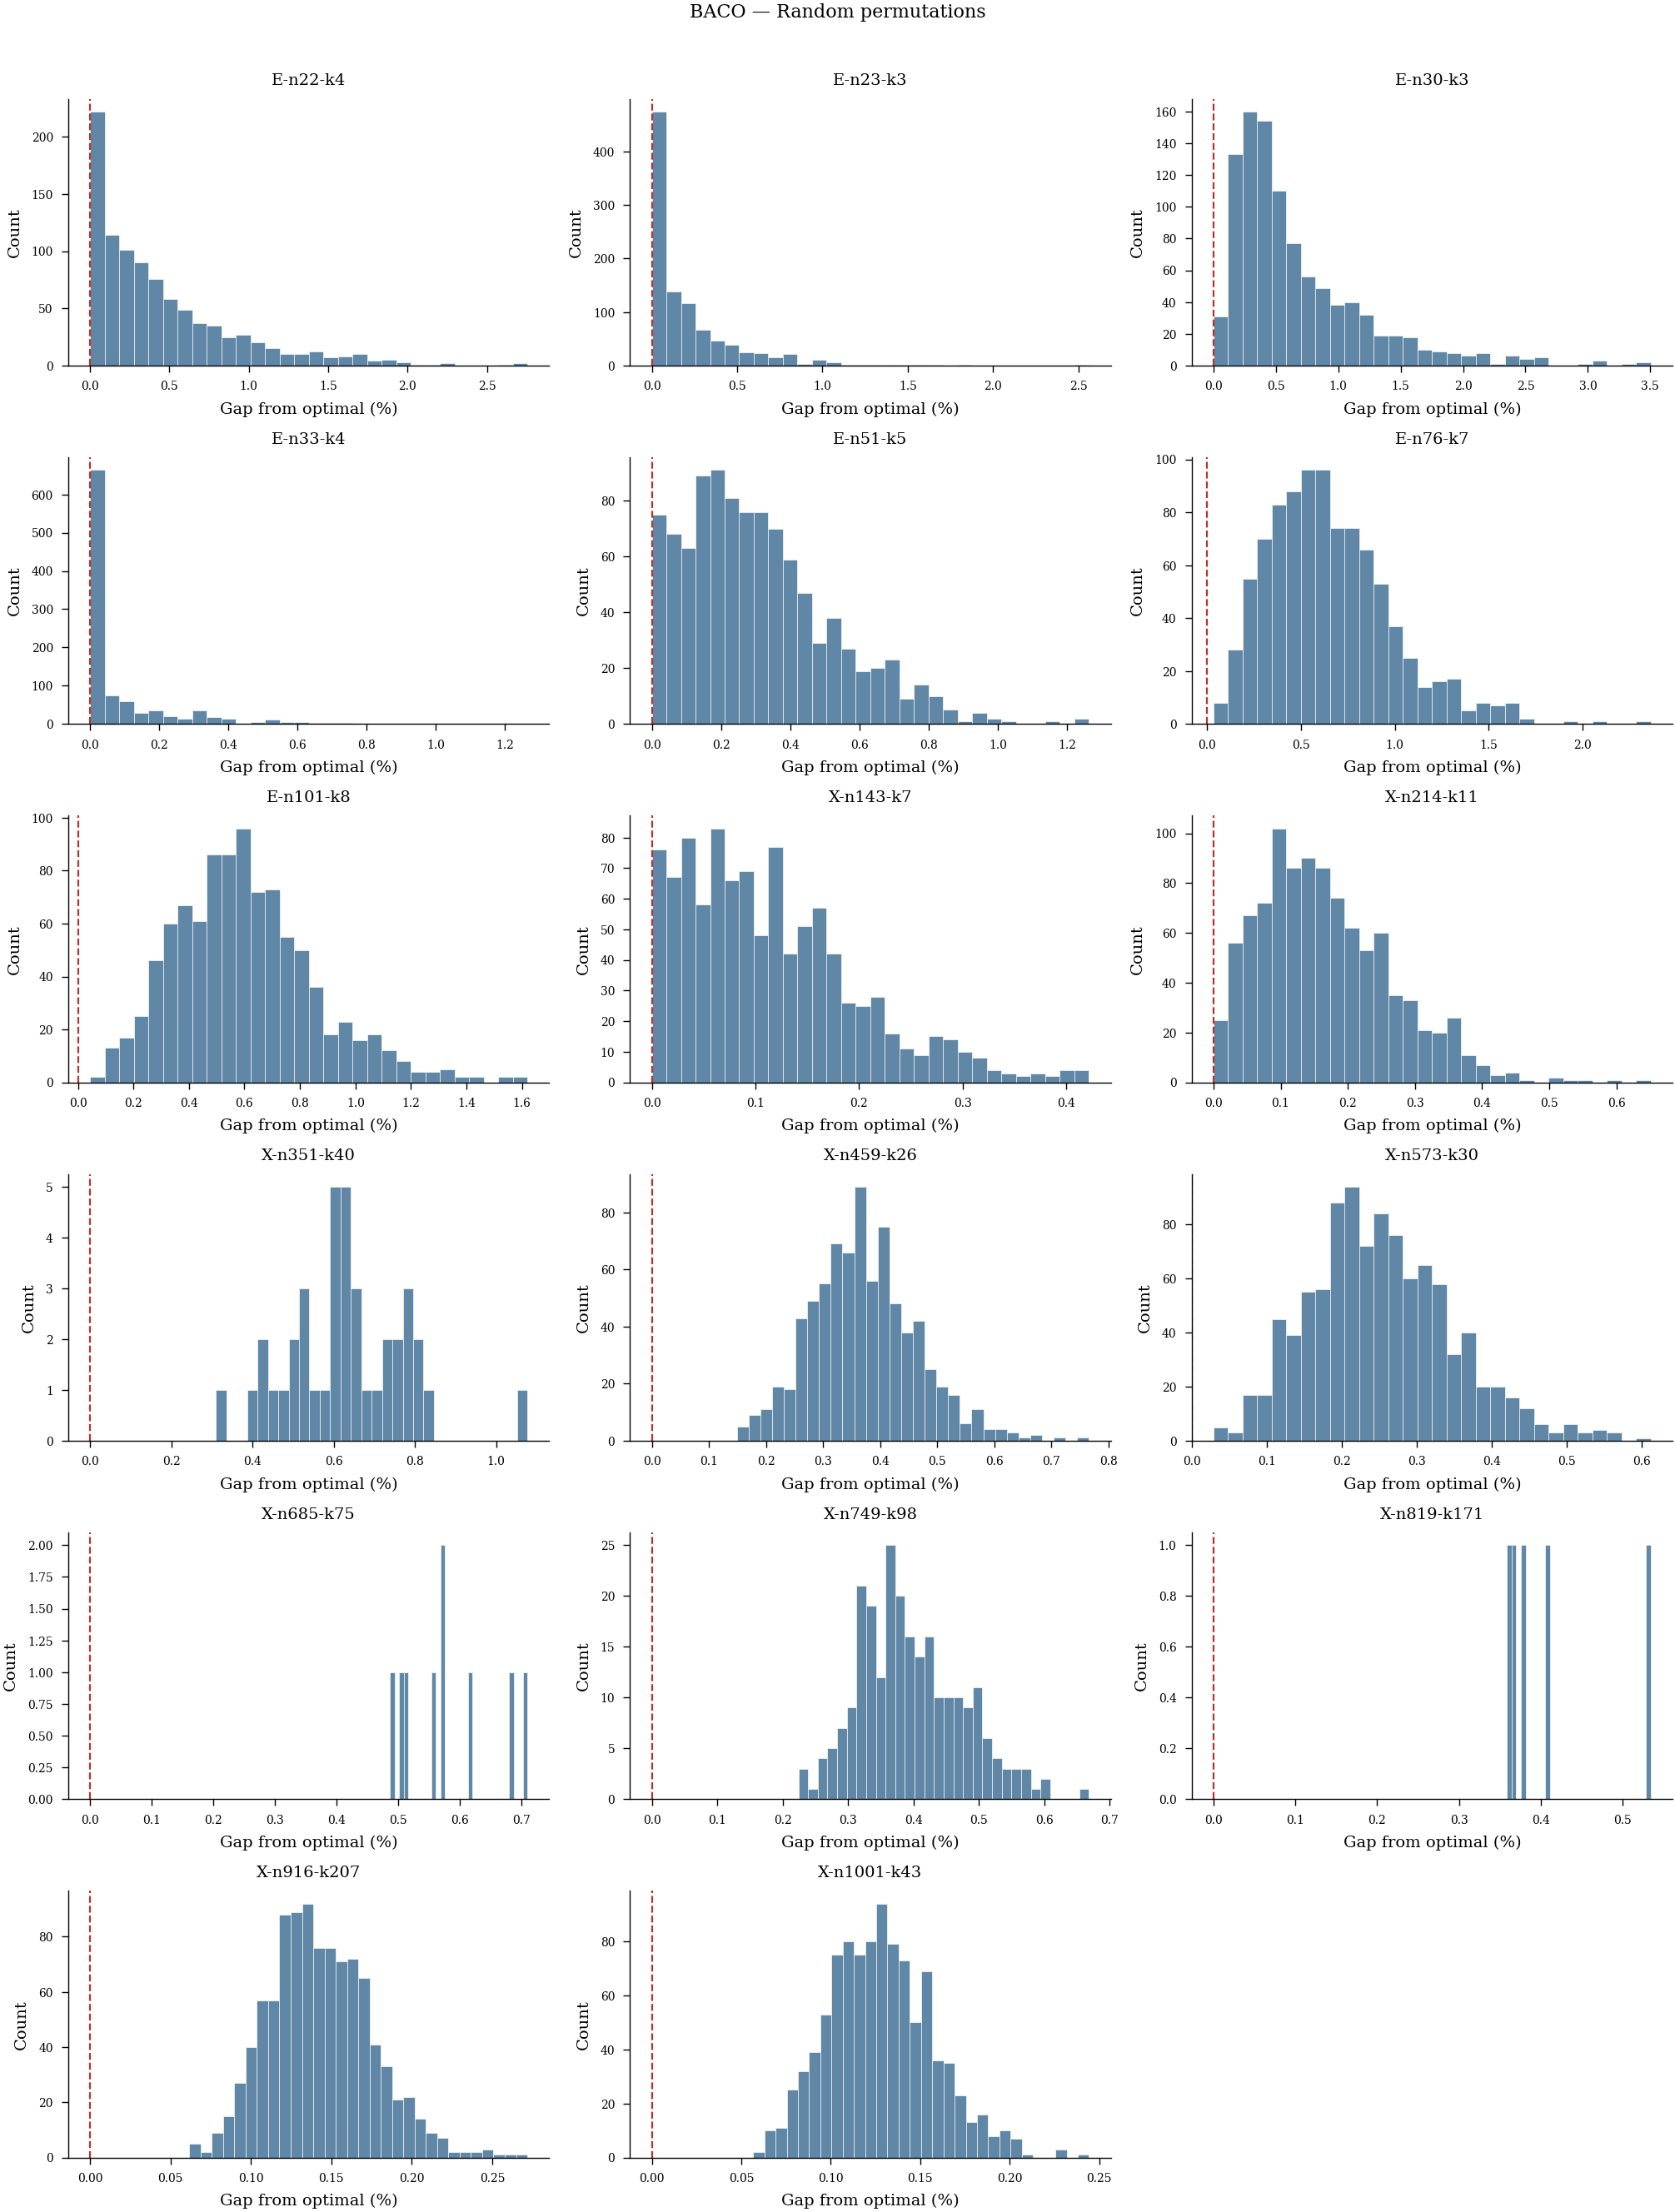

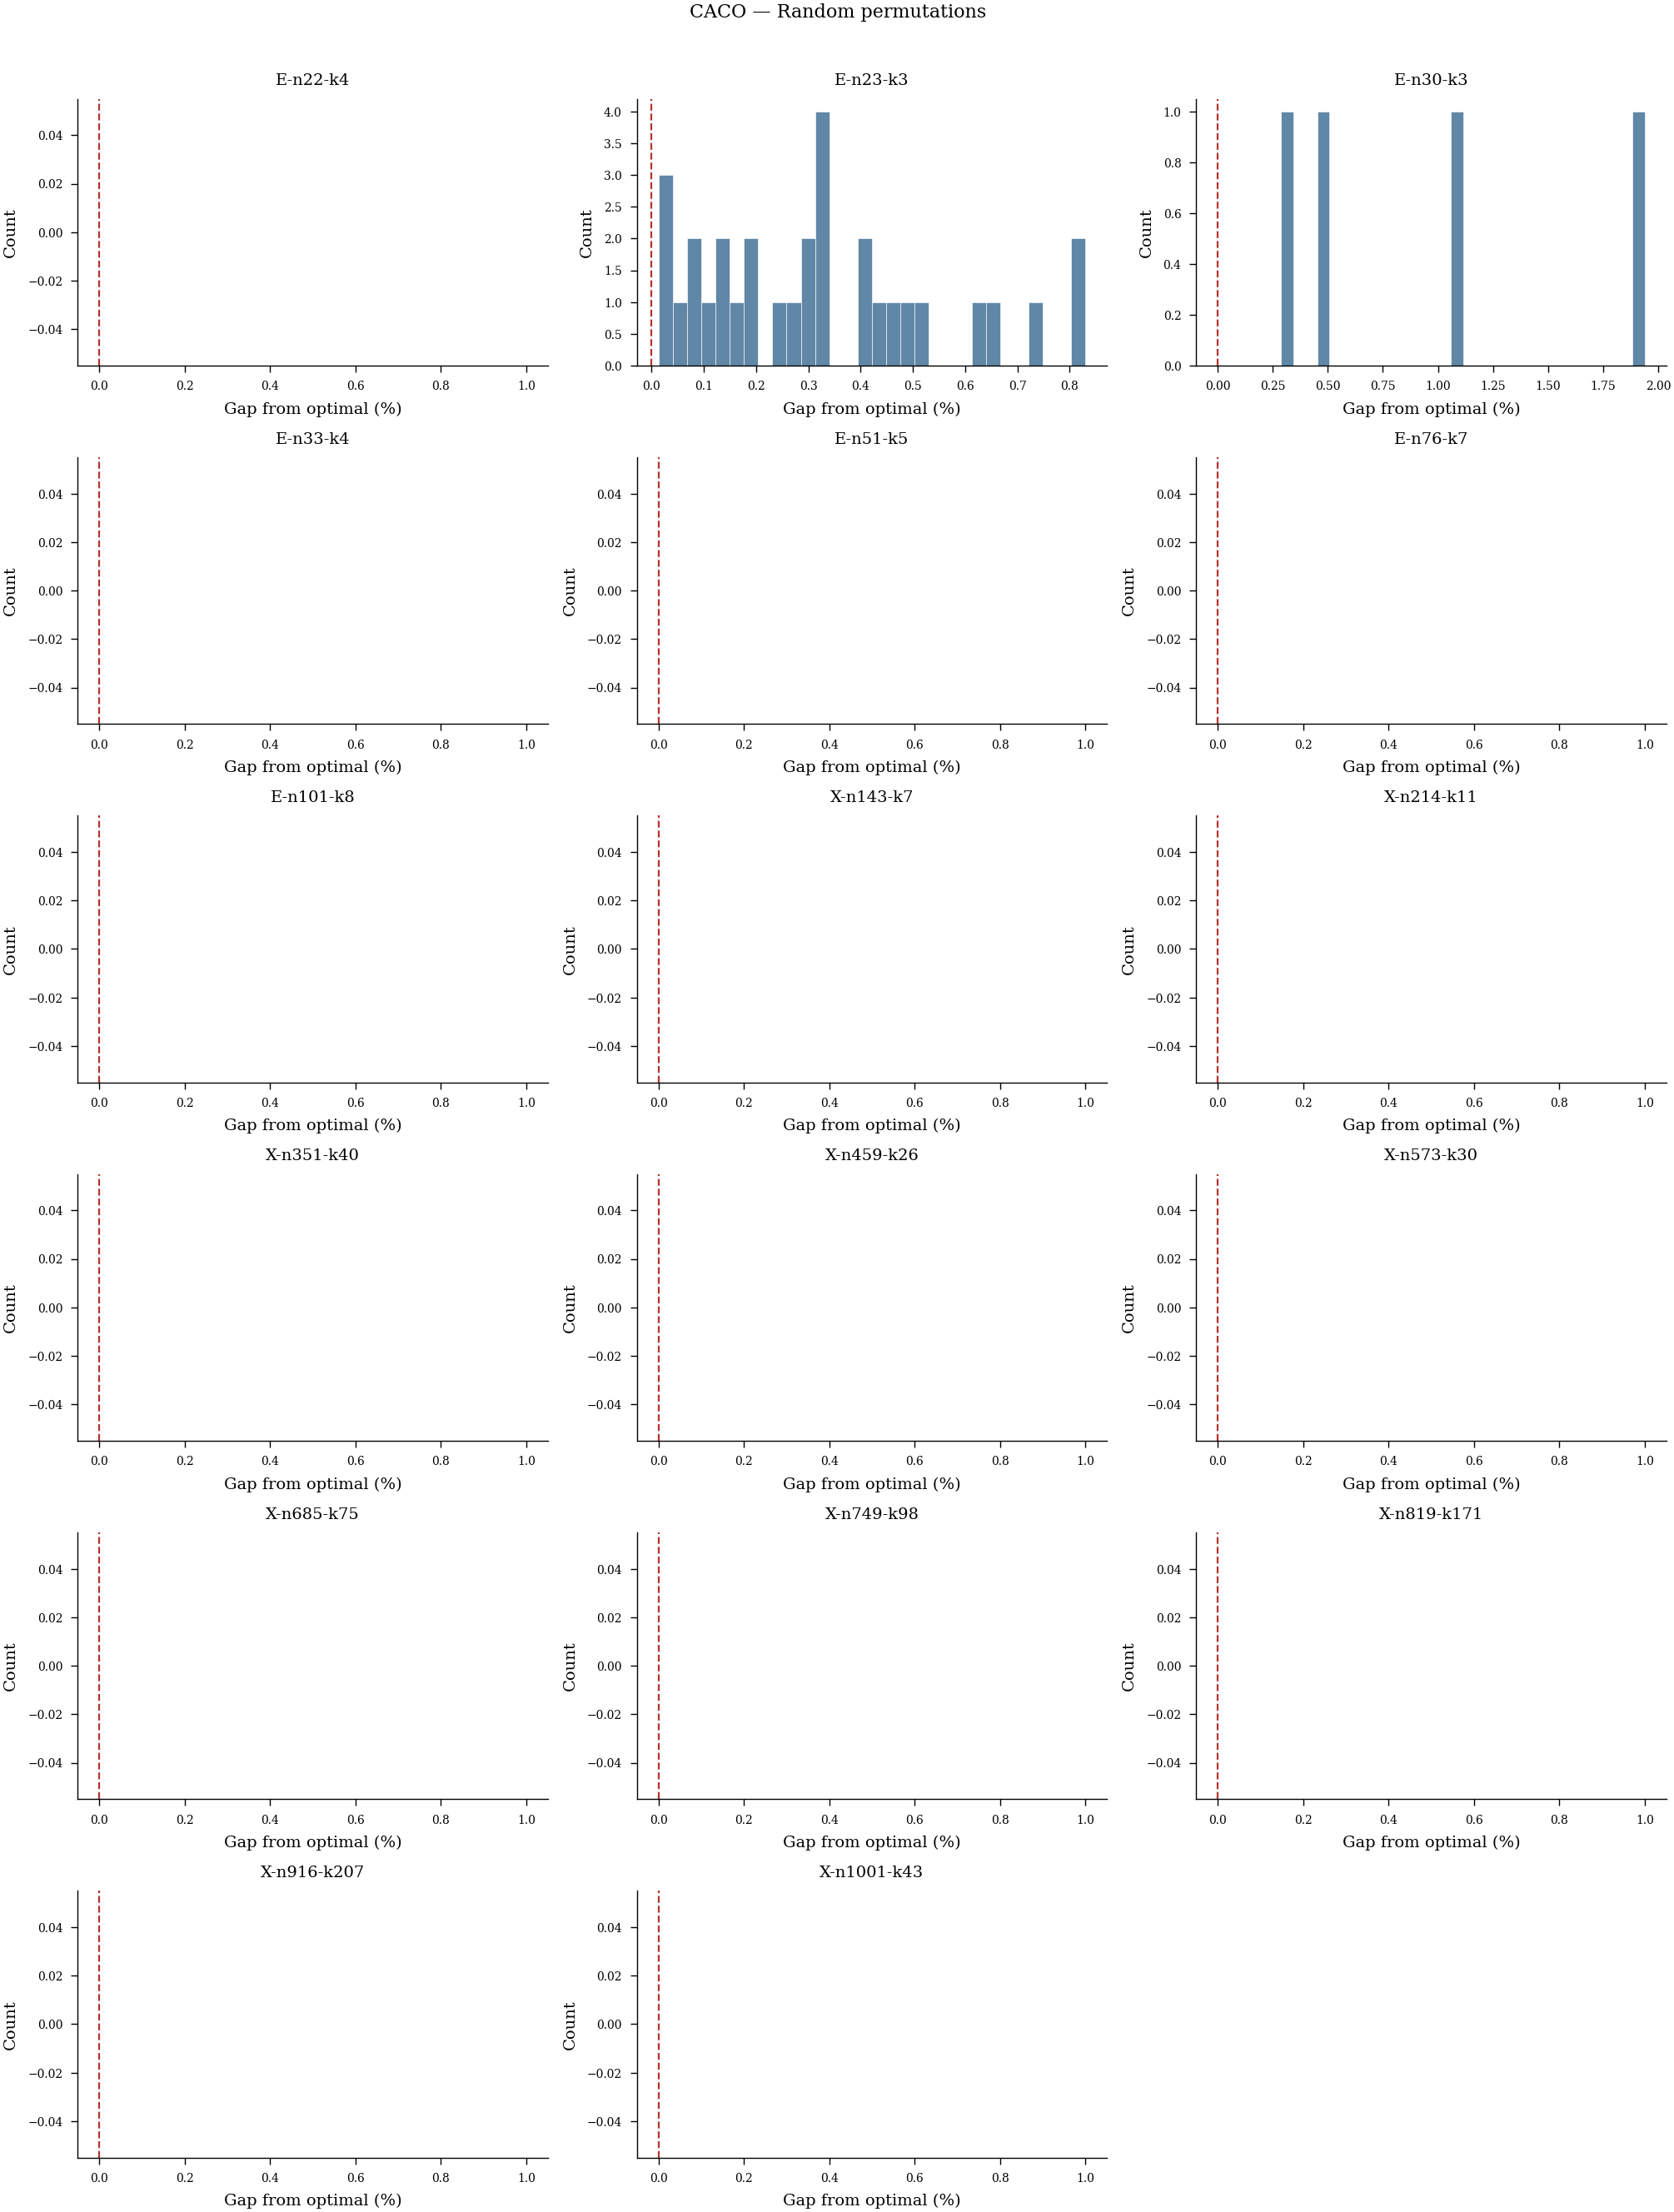

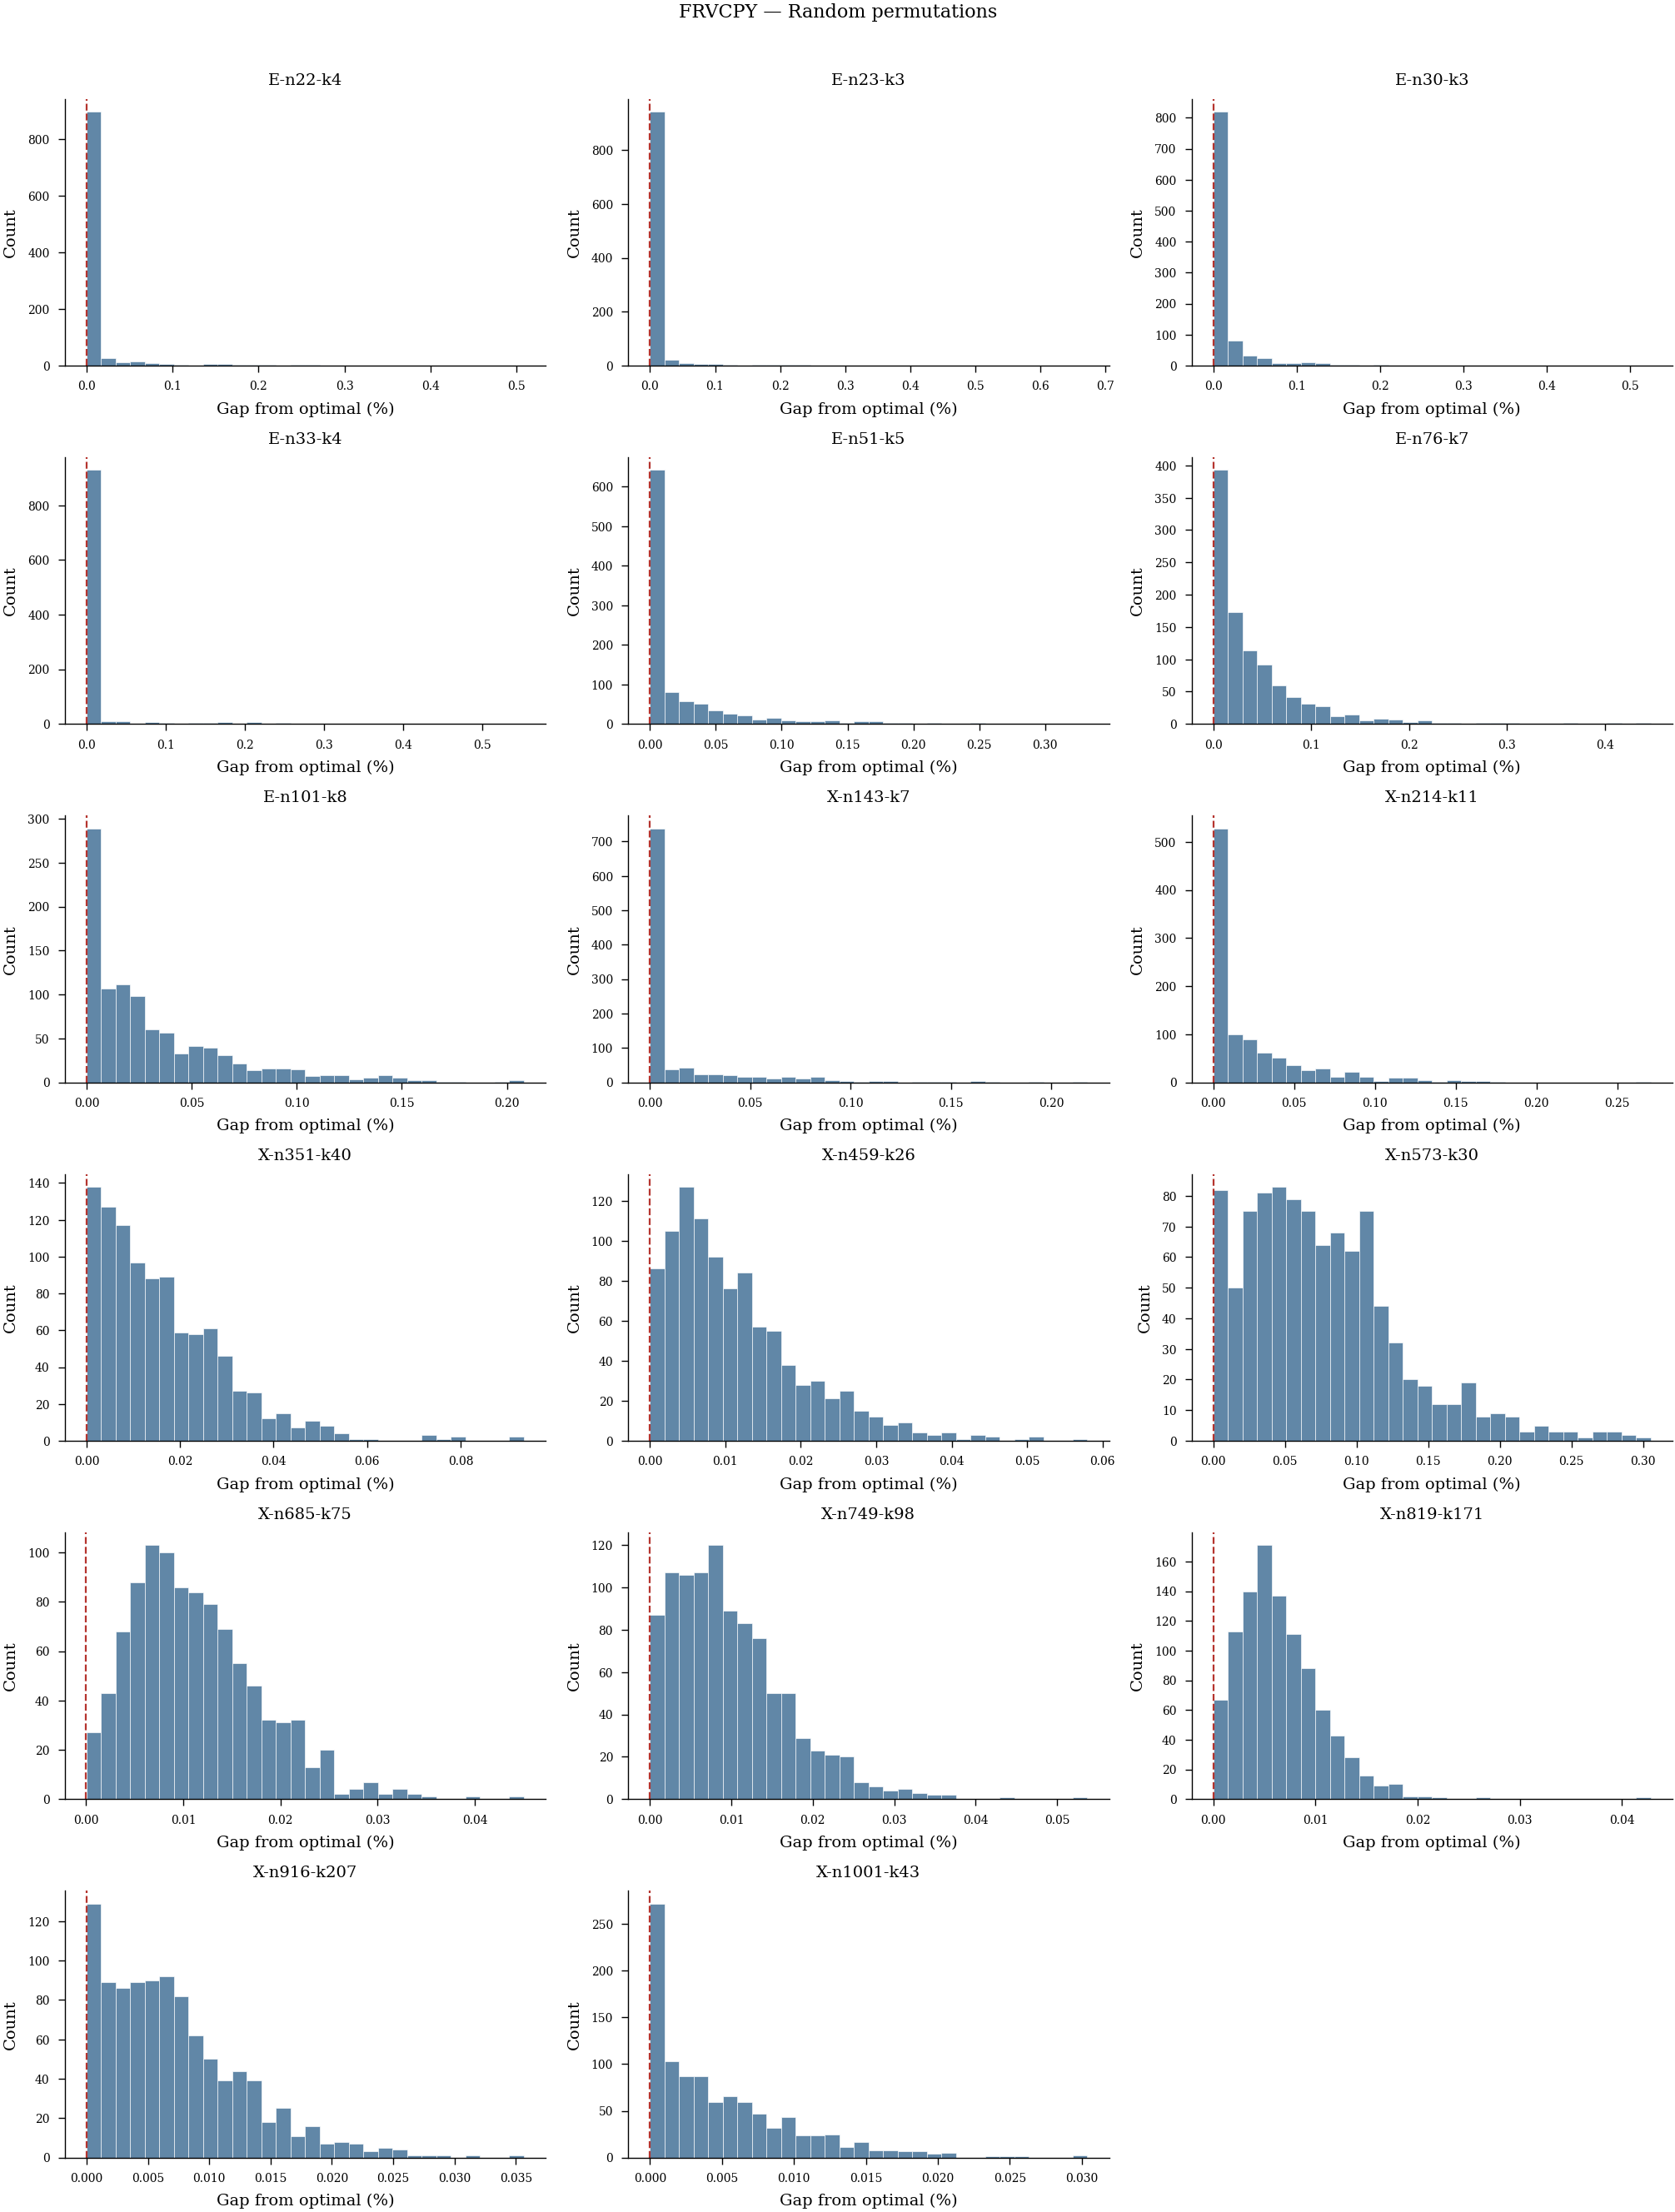

KeyError: 'montoya'

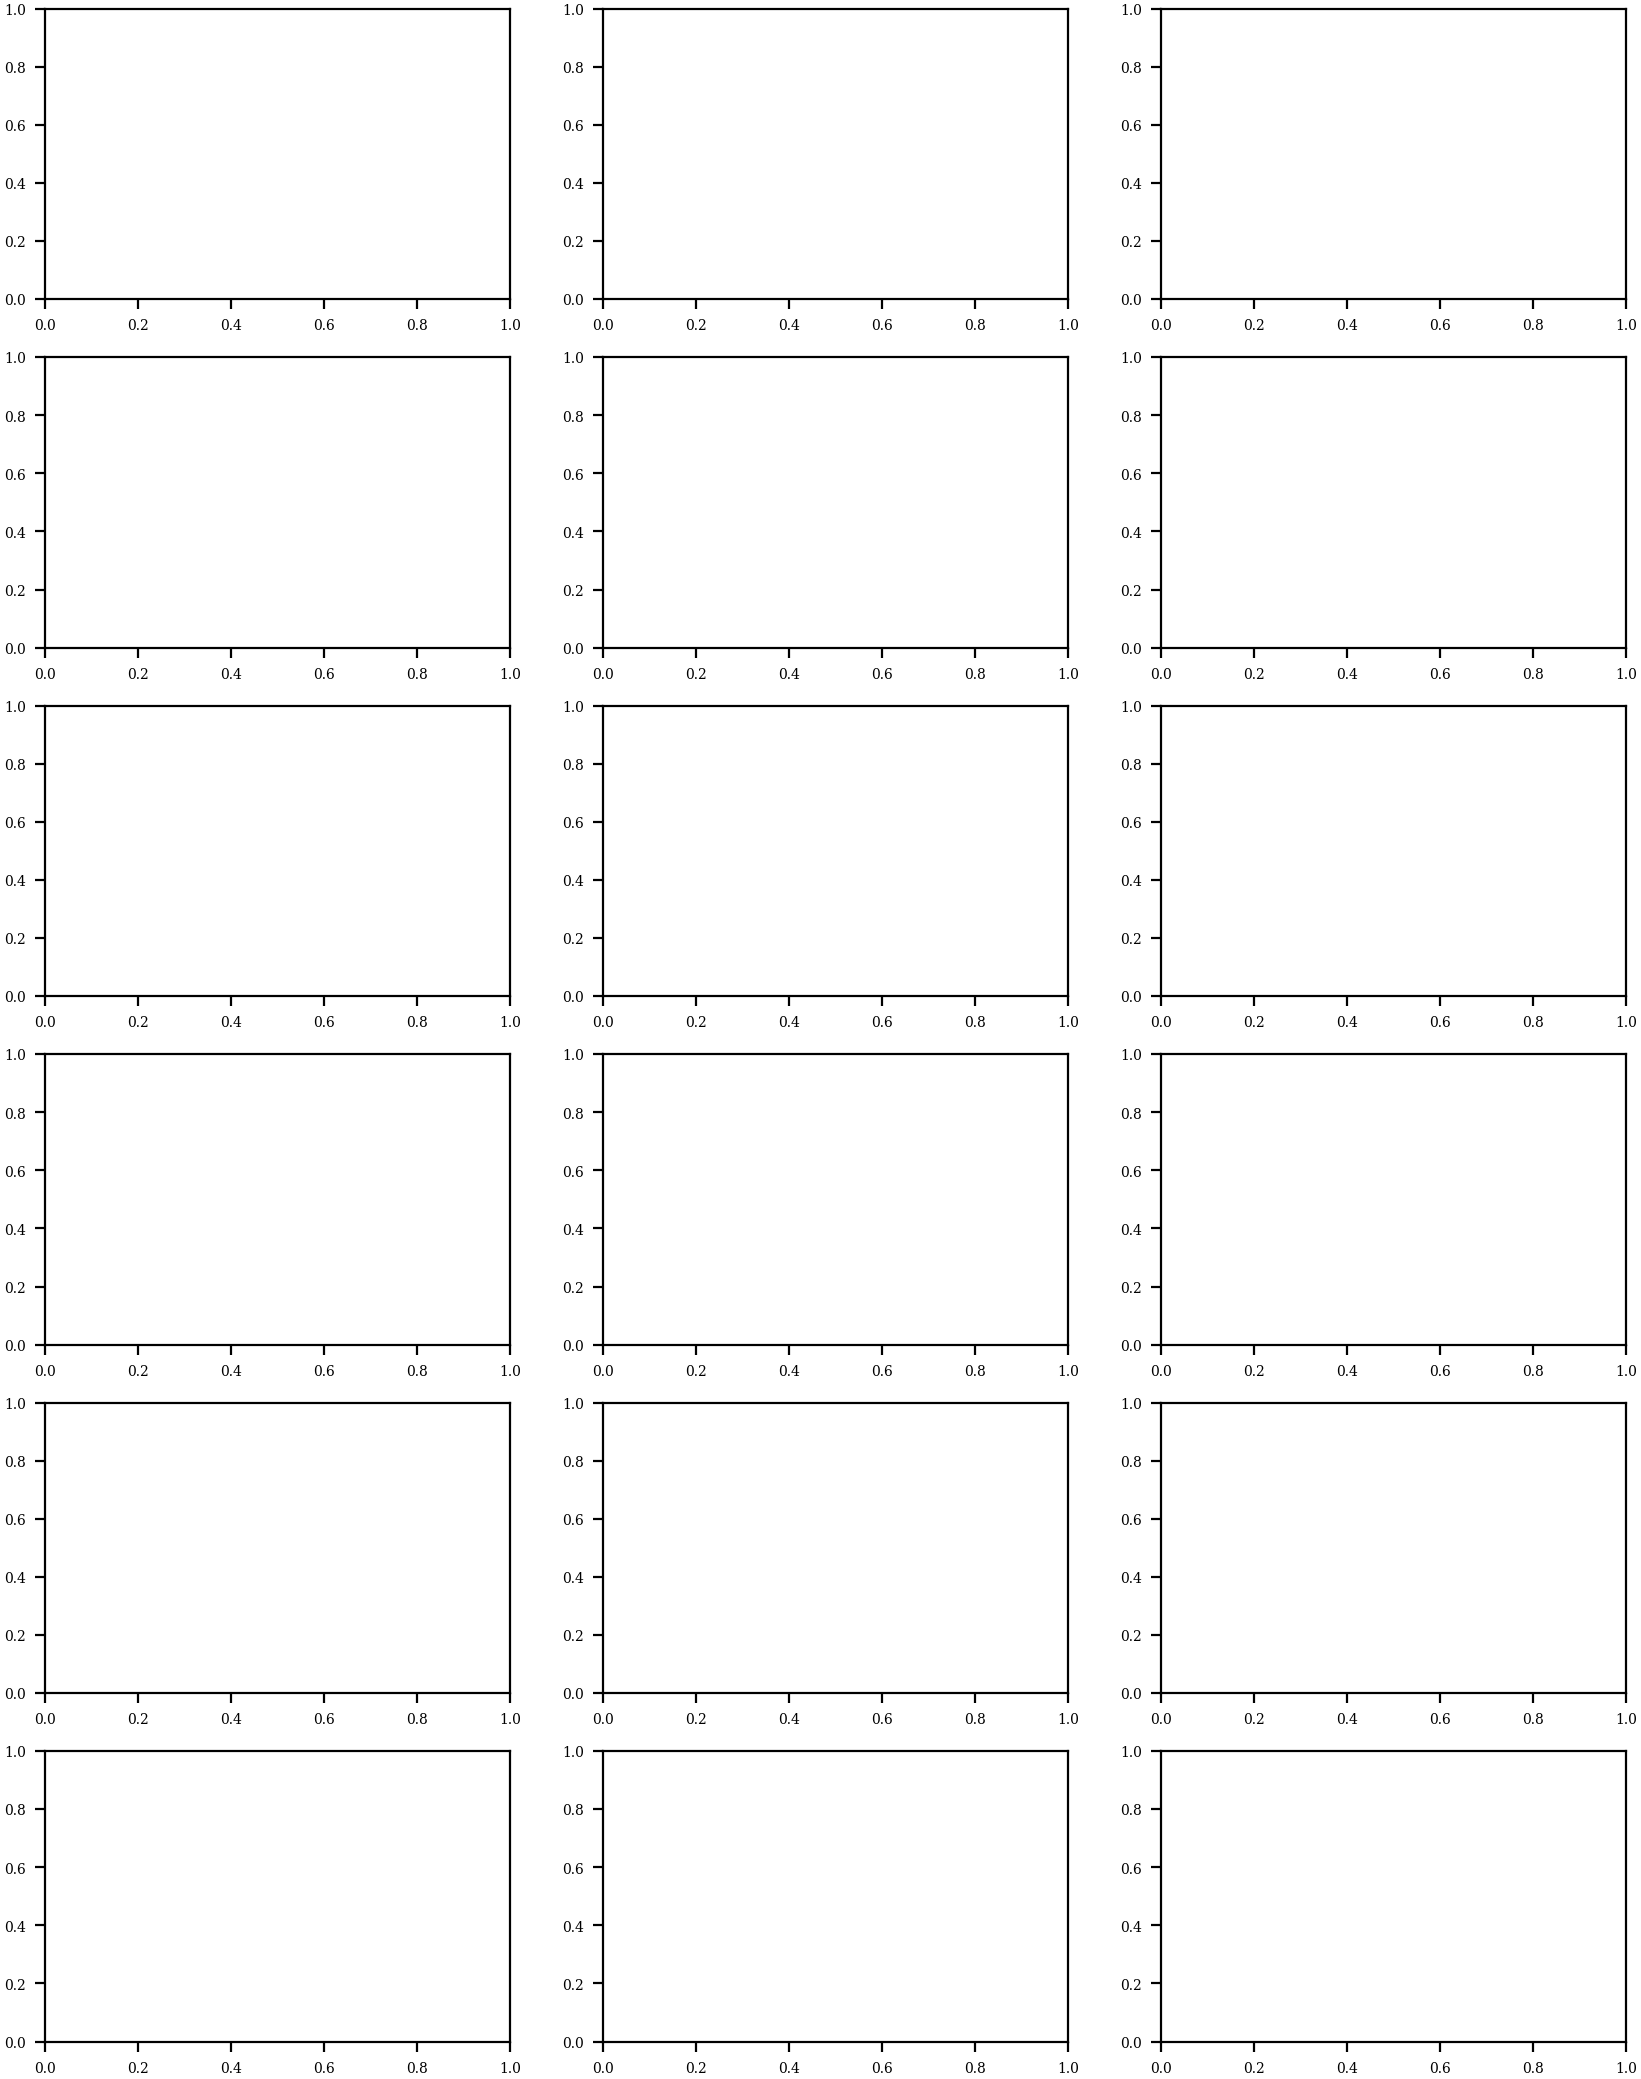

In [6]:
for alg_label, cost_key, solved_key in ALGORITHMS:
    plot_distributions(random_results, alg_label, cost_key, solved_key,
                       perm_type='Random permutations',
                       save_dir=f'../.output/random_{cost_key}')

In [ ]:
plot_boxplots(random_results,
              title='Random permutations — performance gap from optimal (%)',
              save_path='../.output/random_boxplots.png')

In [ ]:
plot_ecdf(random_results,
         title='Random permutations — ECDF of performance gap from optimal (%)',
         save_path='../.output/random_ecdf.png')

## KNN Permutations — Distributions

In [ ]:
for alg_label, cost_key, solved_key in ALGORITHMS:
    plot_distributions(knn_results, alg_label, cost_key, solved_key,
                       perm_type='KNN permutations',
                       save_dir=f'../.output/knn_{cost_key}')

In [ ]:
plot_boxplots(knn_results,
              title='KNN permutations — performance gap from optimal (%)',
              save_path='../.output/knn_boxplots.png')

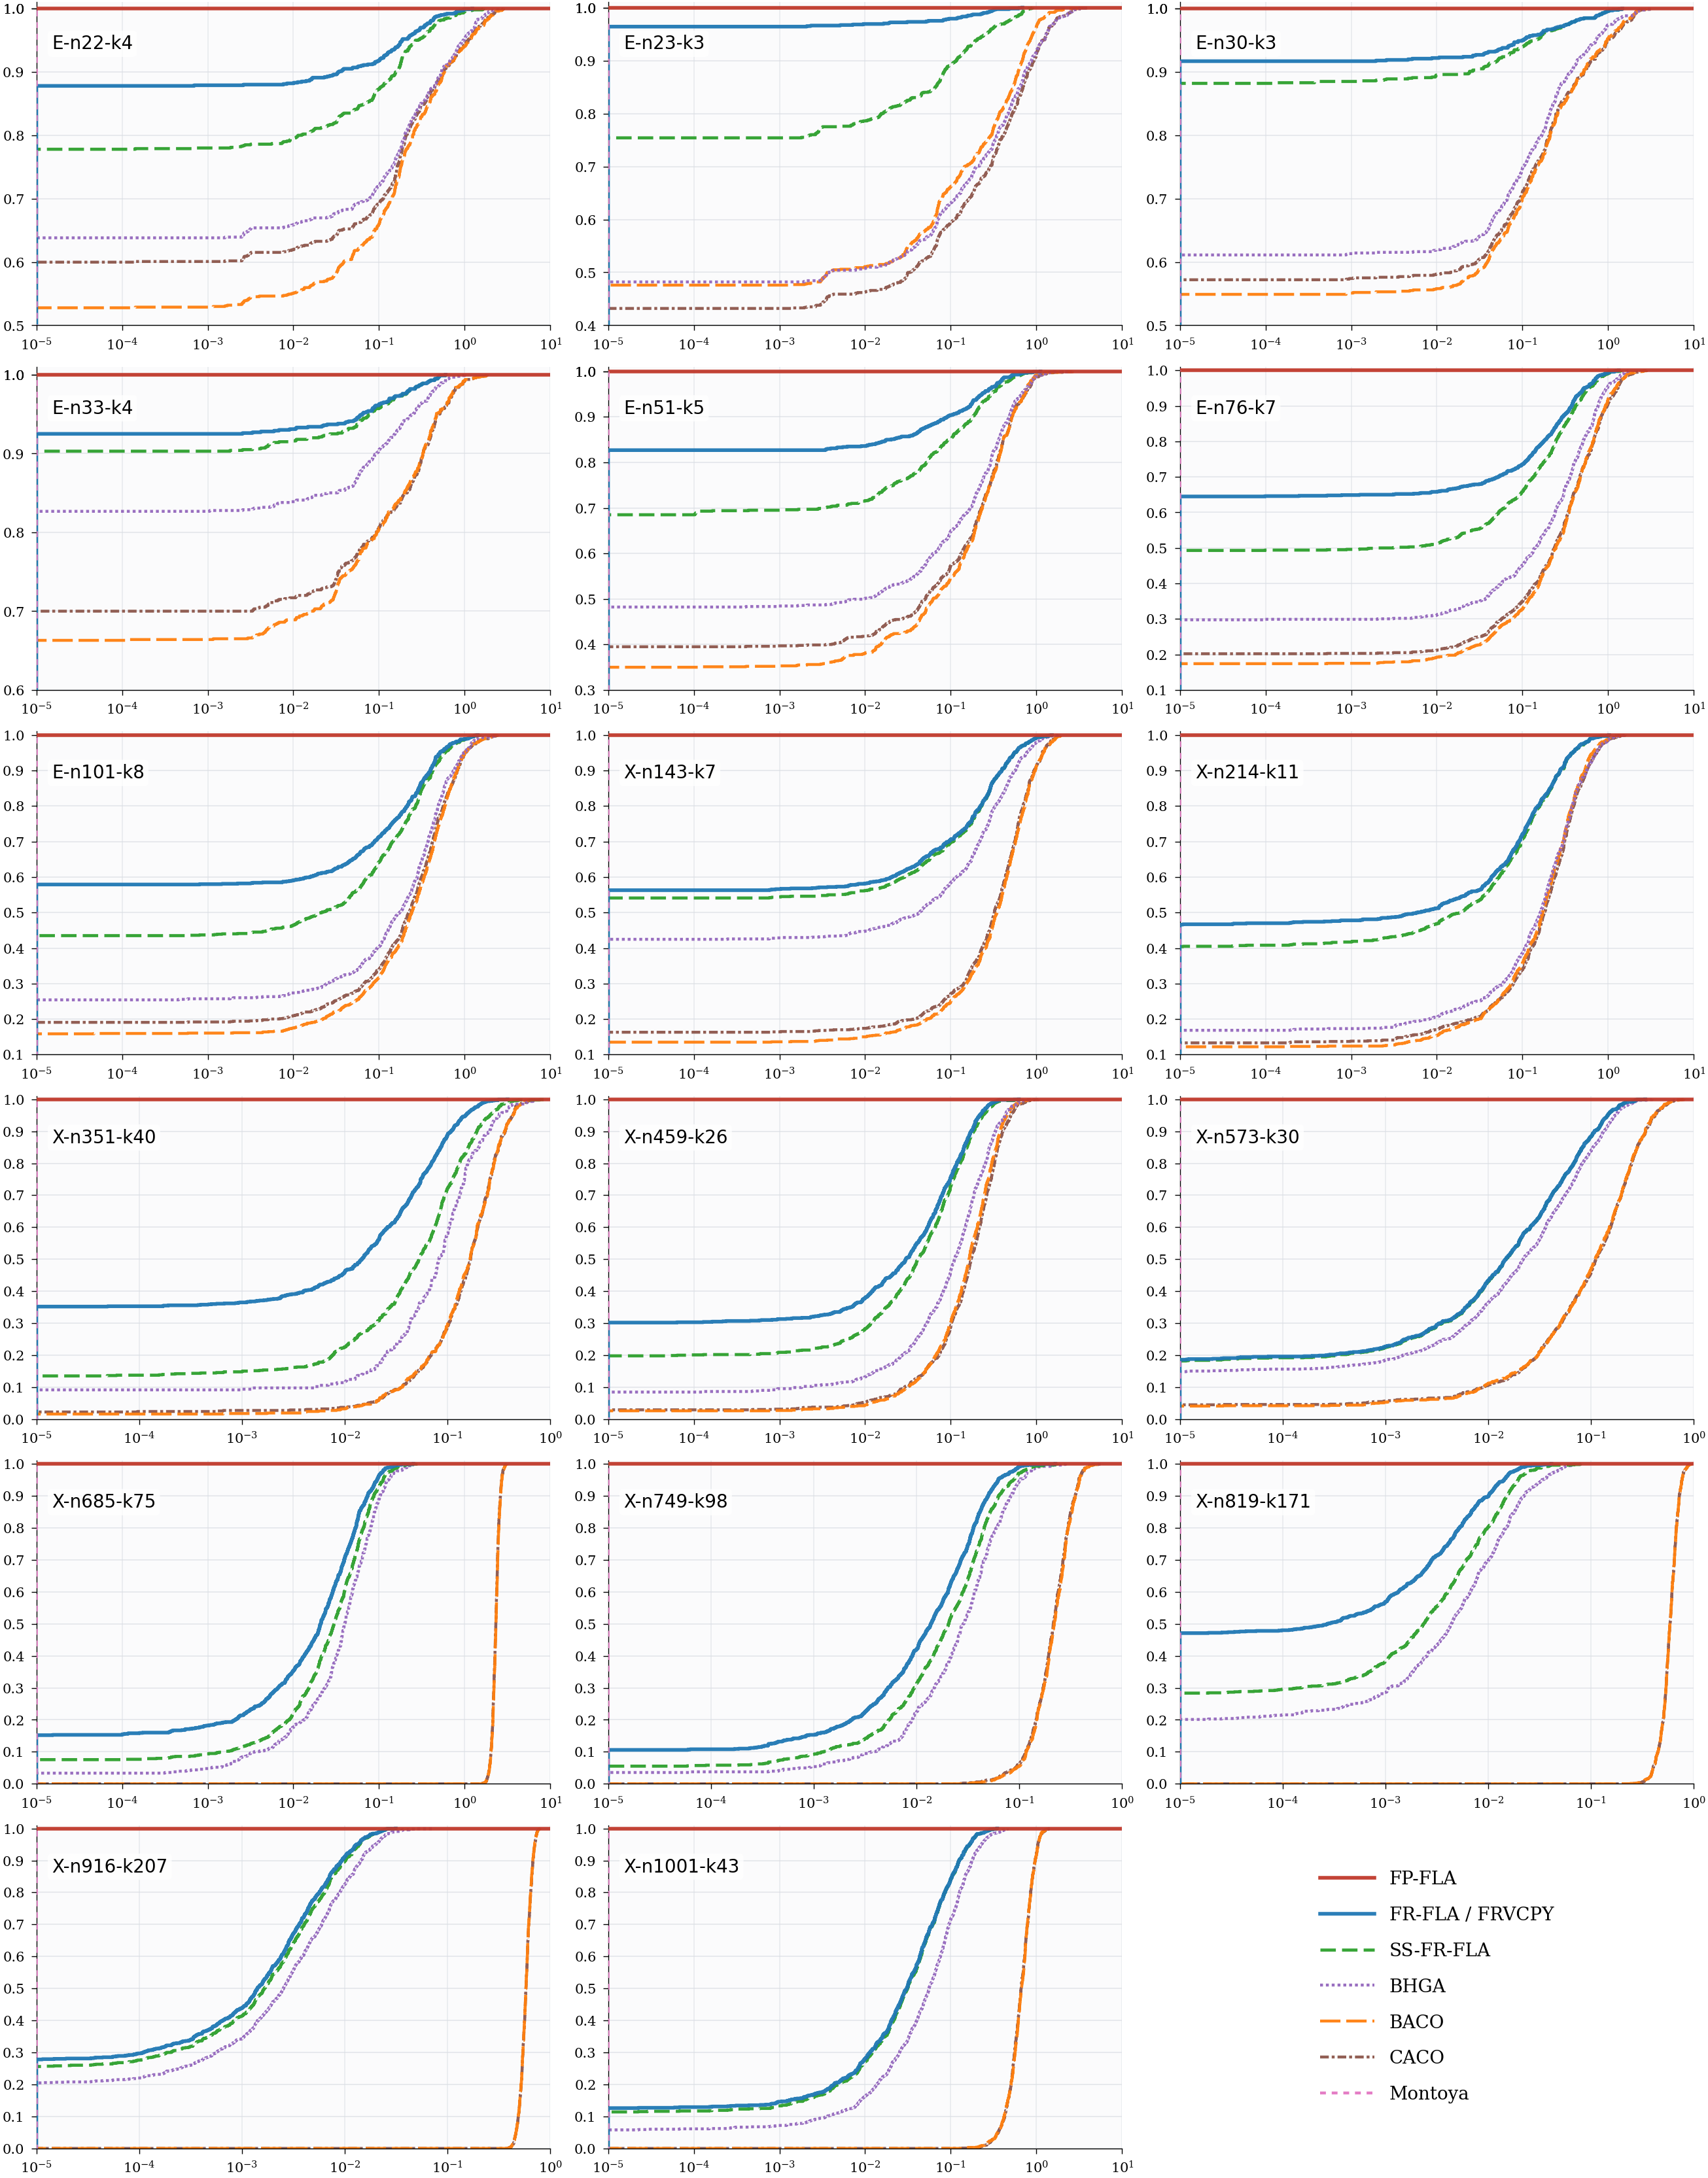

In [7]:
plot_ecdf(knn_results,
         title='KNN permutations — ECDF of performance gap from optimal (%)',
         save_path='../.output/knn_ecdf.png')

## Timing Analysis

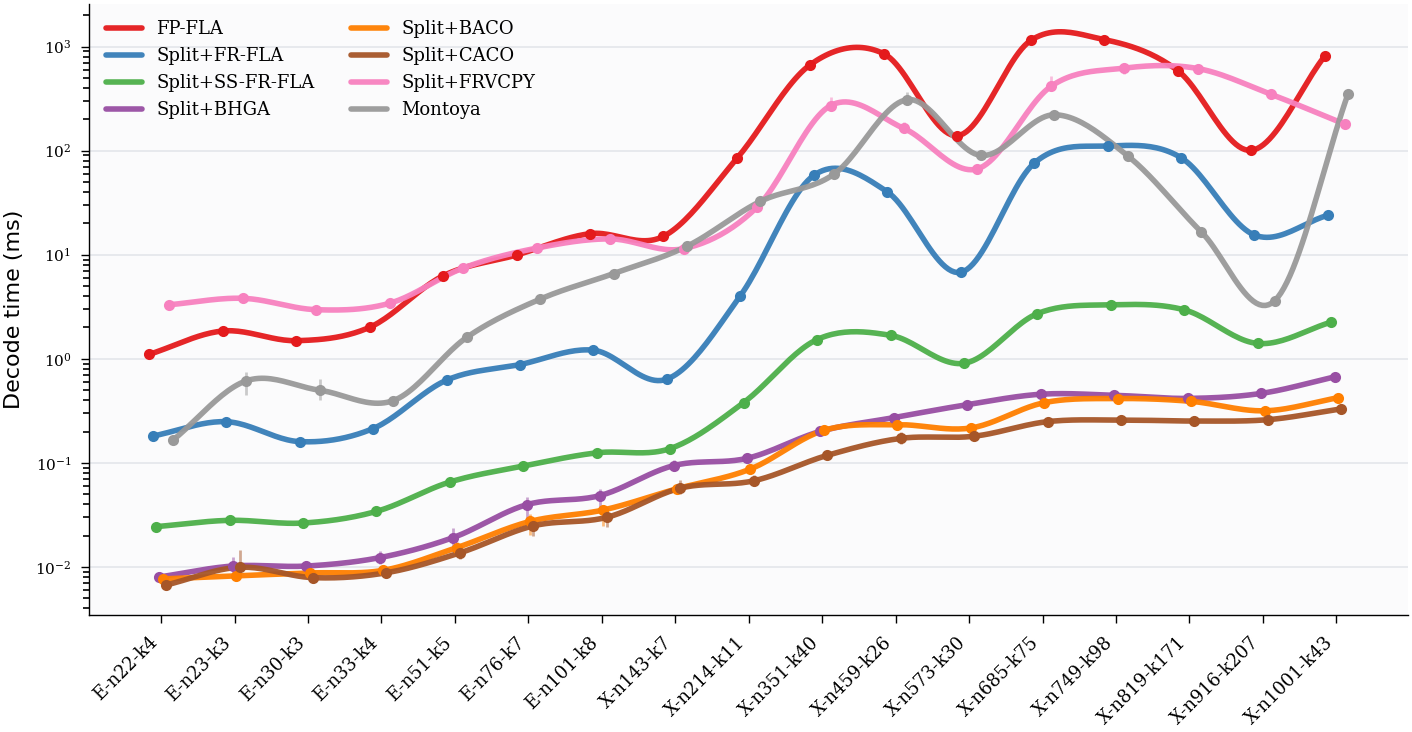

In [10]:
def plot_timing_vs_size(results, title, save_path=None):
    """Median decode time vs instance, with q25 to q75 whiskers."""
    names = sorted_instances(results)
    xs = np.arange(len(names))

    fig, ax = plt.subplots(figsize=(7.2, 3.8))
    sns.despine(ax=ax, top=True, right=True)
    ax.set_facecolor('#fbfbfc')
    ax.grid(axis='y', color='#d9dde3', linewidth=0.6, alpha=0.7, zorder=0)
    ax.grid(axis='x', visible=False)
    offsets = np.linspace(-0.16, 0.16, len(TIMING_PIPELINES))
    timing_labels = {
        'Optimal': 'FP-FLA',
        'Split+Battery': 'Split+FR-FLA',
        'Split+BatterySingle': 'Split+SS-FR-FLA',
    }

    for idx, ((label, time_fn), color) in enumerate(zip(TIMING_PIPELINES, TIMING_COLORS)):
        medians = np.array([np.median([time_fn(p) for p in results[n]]) for n in names])
        q25 = np.array([np.percentile([time_fn(p) for p in results[n]], 25) for n in names])
        q75 = np.array([np.percentile([time_fn(p) for p in results[n]], 75) for n in names])
        x_pos = xs + offsets[idx]

        smooth_x, smooth_y = _smooth_log_curve(x_pos, medians)
        ax.plot(smooth_x, smooth_y, color=color, linewidth=2.0,
                solid_capstyle='round', alpha=0.95, zorder=3,
                label=timing_labels.get(label, label))
        ax.scatter(x_pos, medians, color=color, s=9, zorder=4)
        ax.errorbar(x_pos, medians,
                    yerr=np.vstack((medians - q25, q75 - medians)),
                    fmt='none', ecolor=color, elinewidth=1.0,
                    capsize=0, alpha=0.5, zorder=1)

    ax.set_xticks(xs)
    ax.set_xticklabels(names, rotation=45, ha='right')
    ax.set_xlabel('')
    ax.set_ylabel('Decode time (ms)', fontsize=8, fontname='Sans')
    ax.set_yscale('log')
    ax.legend(fontsize=6.5, ncol=2, frameon=False)
    _style_ax(ax)
    ax.tick_params(axis='x', labelsize=6.5)
    ax.tick_params(axis='y', labelsize=5.5)
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path)
    plt.show()


# plot_timing_vs_size(random_results, 'Random — median decode time vs size',
#                     save_path='../.output/timing_vs_size_random.png')
plot_timing_vs_size(knn_results, 'KNN — median decode time vs size',
                    save_path='../.output/timing_vs_size_knn.png')

KeyError: 't_montoya'

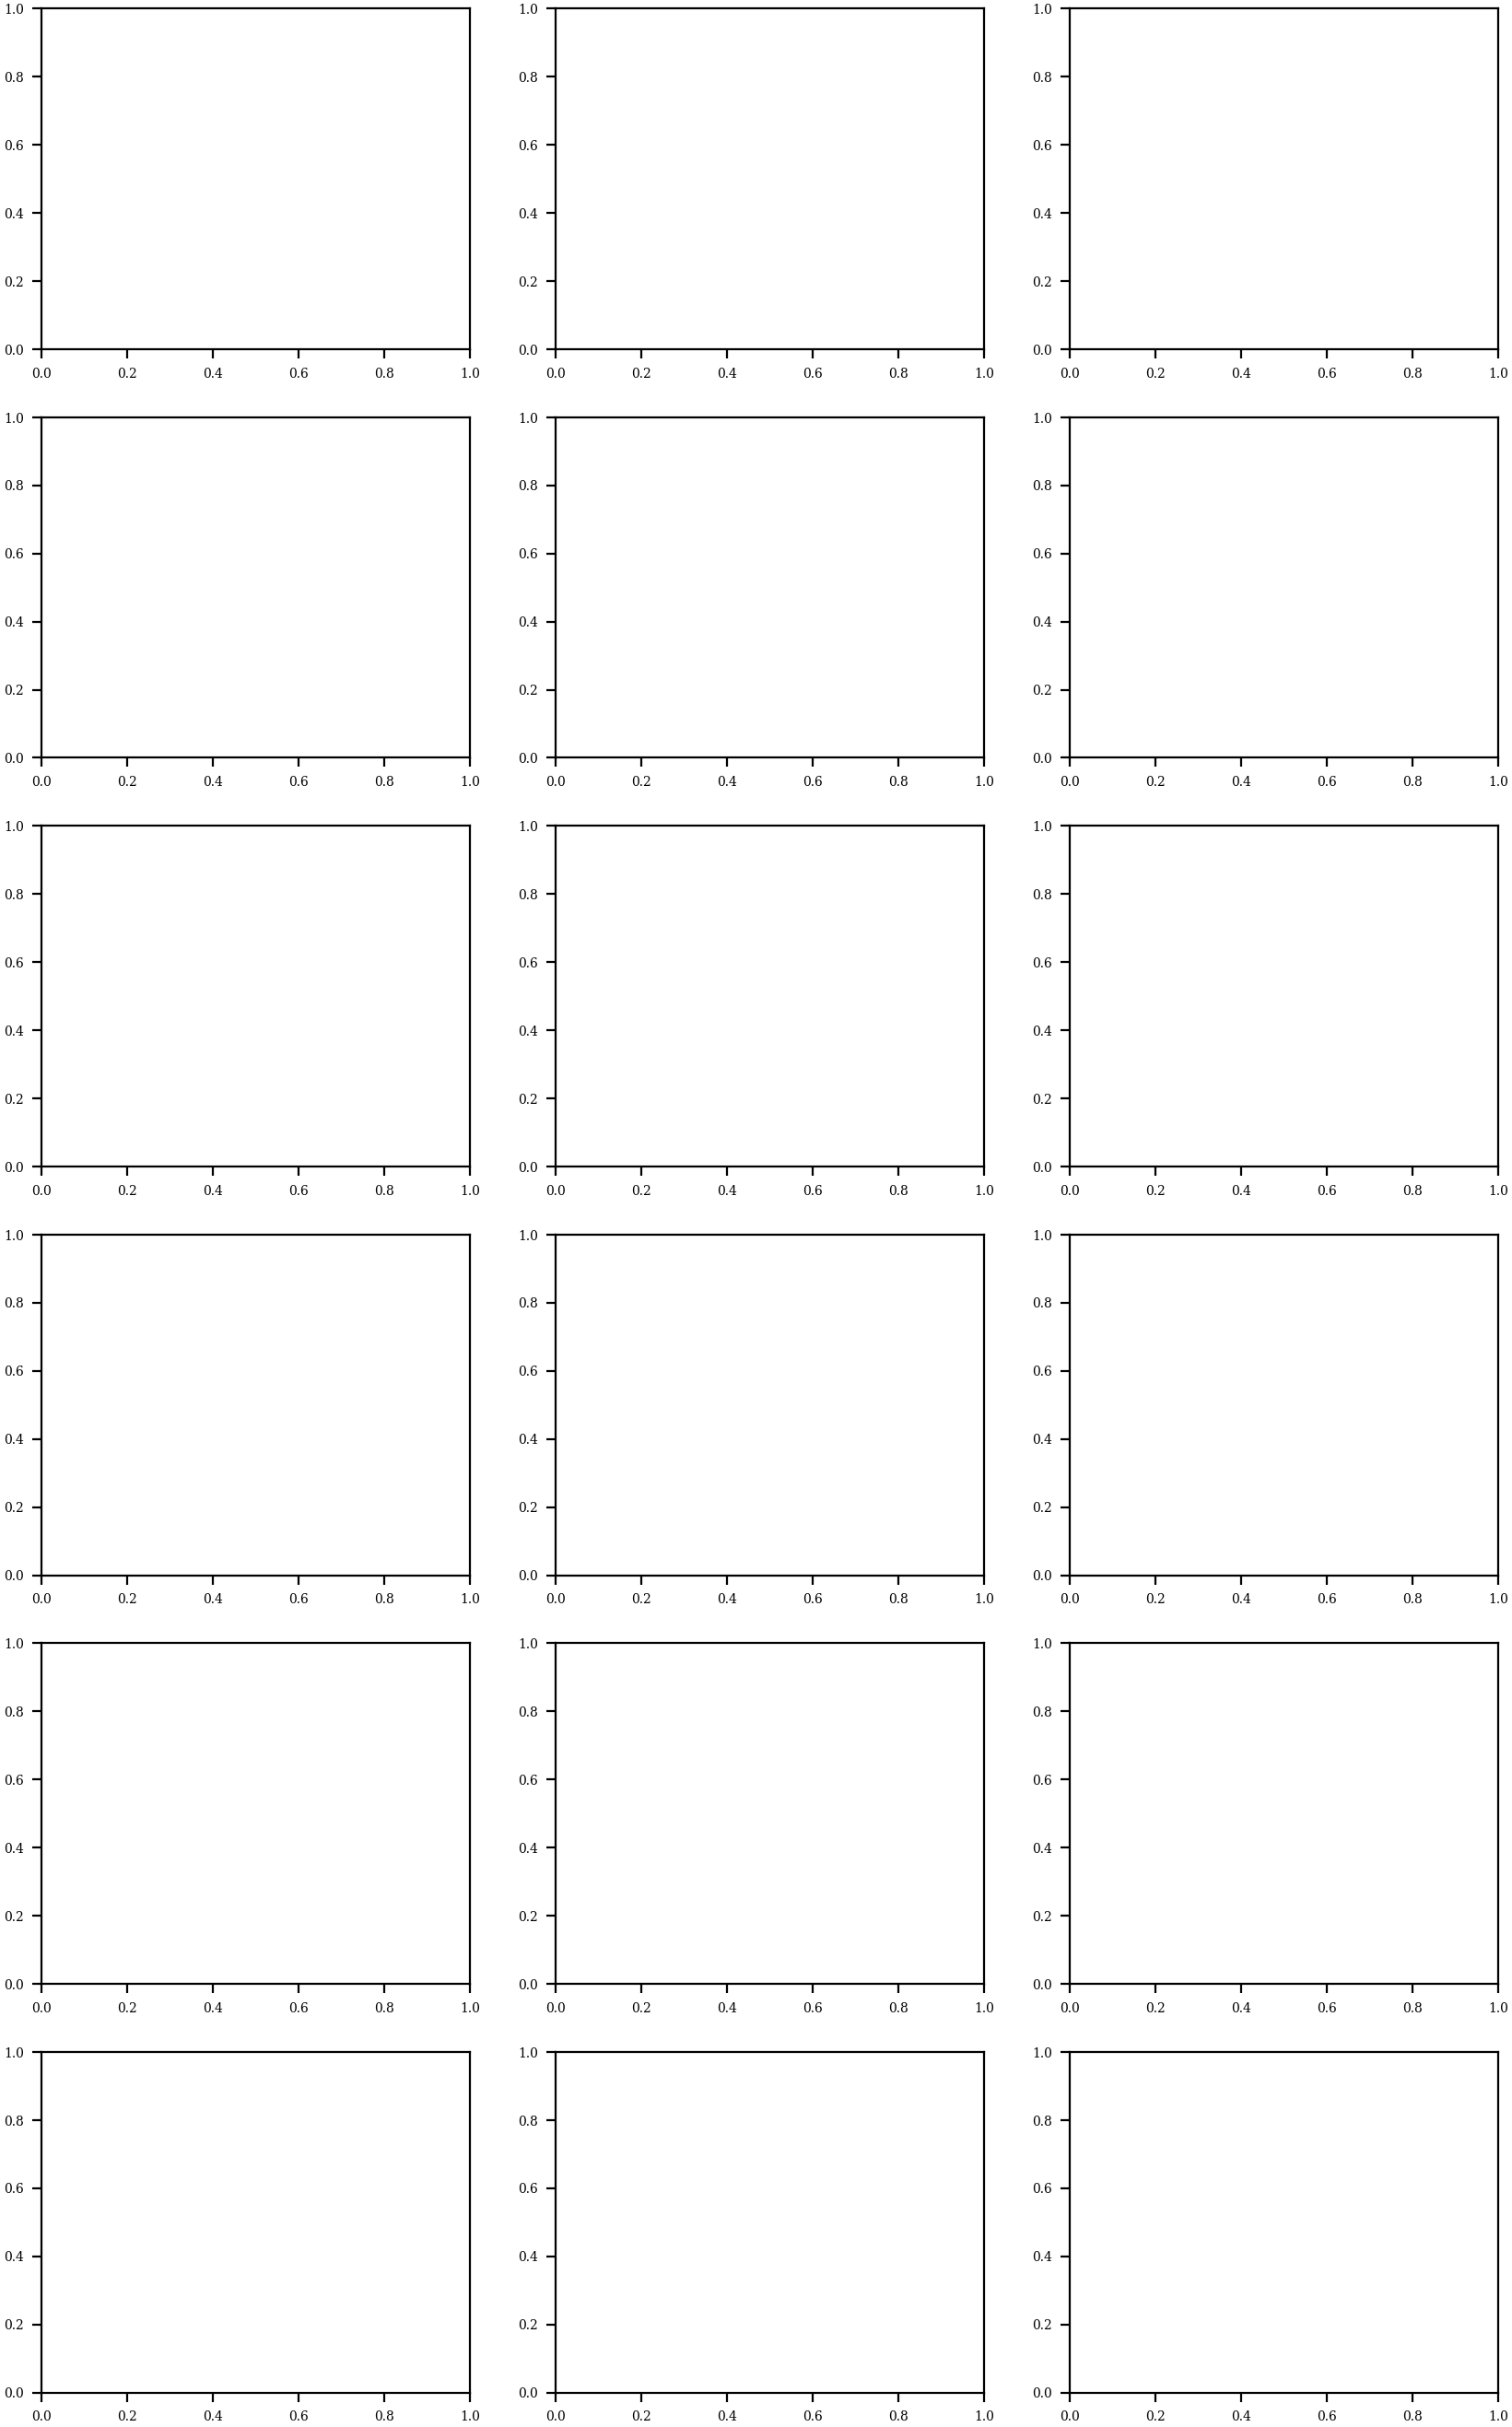

In [9]:
def plot_timing_boxplots(results, title, save_path=None):
    """Box plots of per-permutation pipeline time per instance."""
    names = sorted_instances(results)
    n = len(names)
    cols = 3
    rows = math.ceil(n / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(3.4 * cols, 2.8 * rows))
    axes_flat = axes.flatten()

    timing_labels = {
        'Optimal': 'FP-FLA',
        'Split+Battery': 'Split+FR-FLA',
        'Split+BatterySingle': 'Split+SS-FR-FLA',
    }
    labels = [timing_labels.get(label, label) for label, _ in TIMING_PIPELINES]

    for ax, name in zip(axes_flat, names):
        perms = results[name]
        data = [[time_fn(p) for p in perms] for _, time_fn in TIMING_PIPELINES]

        bp = ax.boxplot(data, labels=labels, patch_artist=True, widths=0.5,
                        medianprops=dict(color='black', linewidth=1.0),
                        flierprops=dict(marker='o', markersize=1.0, alpha=0.3, linestyle='none'),
                        whiskerprops=dict(linewidth=0.6), capprops=dict(linewidth=0.6),
                        boxprops=dict(linewidth=0.6))
        for patch, color in zip(bp['boxes'], TIMING_COLORS):
            patch.set_facecolor(color)
            patch.set_alpha(0.7)
        ax.set_title(f"{name} (n={customer_count(name)})", fontsize=7)
        ax.set_ylabel('Decode time (µs)')
        ax.tick_params(axis='x', labelsize=3.5, rotation=45)
        _style_ax(ax)

    for ax in axes_flat[n:]:
        ax.set_visible(False)

    fig.suptitle(title, fontsize=8, y=1.01)
    fig.tight_layout()
    if save_path:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path)
    plt.show()


plot_timing_boxplots(random_results,
                     title='Random permutations — decode time per pipeline',
                     save_path='../.output/timing_boxplots_random.png')
plot_timing_boxplots(knn_results,
                     title='KNN permutations — decode time per pipeline',
                     save_path='../.output/timing_boxplots_knn.png')

## Summary Tables

In [ ]:
def build_performance_table(results, perm_label):
    """Build solved-rate and gap-percentile performance tables."""
    names = sorted_instances(results)
    solved_rows = []
    gap_rows = []
    aggregate_solved = {alg_label: 0 for alg_label, _, _ in ALGORITHMS}
    aggregate_total = {alg_label: 0 for alg_label, _, _ in ALGORITHMS}

    for name in names:
        perms = results[name]
        n_total = len(perms)
        solved_row = {'Instance': name}
        gap_row = {'Instance': name}

        for alg_label, cost_key, solved_key in ALGORITHMS:
            if solved_key:
                solved = [p for p in perms if p.get(solved_key, True)]
            else:
                solved = perms

            solved_pct = 100 * len(solved) / n_total if n_total else 0.0
            solved_row[alg_label] = f"{solved_pct:.1f}%"
            aggregate_solved[alg_label] += len(solved)
            aggregate_total[alg_label] += n_total

            gaps = [100 * (p[cost_key] - p['combined']) / p['combined'] for p in solved]
            if gaps:
                arr = np.array(gaps)
                non_zero_pct = 100 * np.mean(arr != 0.0)
                p90 = np.percentile(arr, 90)
                p95 = np.percentile(arr, 95)
                gap_row[alg_label] = f"{non_zero_pct:.1f}% non-zero | P90: {p90:.2f}% | P95: {p95:.2f}%"
            else:
                gap_row[alg_label] = "— | — | —"

        solved_rows.append(solved_row)
        gap_rows.append(gap_row)

    aggregate_row = {'Instance': 'Aggregate'}
    for alg_label, _, _ in ALGORITHMS:
        total = aggregate_total[alg_label]
        solved_pct = 100 * aggregate_solved[alg_label] / total if total else 0.0
        aggregate_row[alg_label] = f"{solved_pct:.1f}%"
    solved_rows.append(aggregate_row)

    solved_df = pd.DataFrame(solved_rows).set_index('Instance')
    gap_df = pd.DataFrame(gap_rows).set_index('Instance')
    solved_df.columns.name = f"{perm_label} solved"
    gap_df.columns.name = f"{perm_label} gaps"
    return solved_df, gap_df


print("Performance tables")
print()
print("=== Random Permutations: solved percentage ===")
df_rand_solved, df_rand_gap = build_performance_table(random_results, 'Random')
df_rand_solved.to_csv('../.output/performance_table_random_solved.csv')
display(df_rand_solved)

print()
print("=== Random Permutations: non-zero gap, P90, P95 ===")
df_rand_gap.to_csv('../.output/performance_table_random_gaps.csv')
display(df_rand_gap)

print()
print("=== KNN Permutations: solved percentage ===")
df_knn_solved, df_knn_gap = build_performance_table(knn_results, 'KNN')
df_knn_solved.to_csv('../.output/performance_table_knn_solved.csv')
display(df_knn_solved)

print()
print("=== KNN Permutations: non-zero gap, P90, P95 ===")
df_knn_gap.to_csv('../.output/performance_table_knn_gaps.csv')
display(df_knn_gap)

In [ ]:
def build_timing_table(results, perm_label):
    """Build a timing table: instances x pipelines with mean +/- std (in µs)."""
    names = sorted_instances(results)
    rows = []
    for name in names:
        perms = results[name]
        row = {'Instance': name}
        for label, time_fn in TIMING_PIPELINES:
            times = [time_fn(p) for p in perms]
            arr = np.array(times)
            row[label] = f"{arr.mean():.0f} ± {arr.std():.0f}"
        rows.append(row)

    df = pd.DataFrame(rows).set_index('Instance')
    df.columns.name = perm_label
    return df


print("Execution time: mean ± std (µs)")
print()
print("=== Random Permutations ===")
df_time_rand = build_timing_table(random_results, 'Random')
df_time_rand.to_csv('../.output/timing_table_random.csv')
display(df_time_rand)

print()
print("=== KNN Permutations ===")
df_time_knn = build_timing_table(knn_results, 'KNN')
display(df_time_knn)